# Retinal Vessel Detection using a Convolutional Autoencoder


In [ ]:

import gc
import glob
import json
import math
import os
import random
import re
import shutil
import subprocess
import sys
import time
import warnings
import zipfile
from pathlib import Path

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy import ndimage
from skimage import exposure, filters, measure, morphology
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.metrics import (auc, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
matplotlib.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                            "grid.alpha": 0.3, "font.size": 9})

SEED = 42


def set_seed(seed: int = SEED) -> None:
    """Make every stochastic step (python / numpy / torch) reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)


CONFIG = {

    "DATA_SOURCE": "kaggle",
    "KAGGLE_DATASET": "andrewmvd/drive-digital-retinal-images-for-vessel-extraction",
    "KAGGLE_FALLBACKS": [
        "zionfuo/drive2004",
        "namnguynnnn/drive-vessel",
        "zhz638/drive-dataset",
        "umairinayat/retinal-vessel-segmentation-datasets",
    ],
    "LOCAL_IMAGE_DIR": "/content/drive/MyDrive/DRIVE/images",
    "LOCAL_MASK_DIR":  "/content/drive/MyDrive/DRIVE/masks",
    "IMG_SIZE": 512,
    "N_IMAGES": 20,
    "TRAIN_RATIO": 0.70,

    "PATCH": 128,
    "PATCH_STRIDE": 64,
    "N_PATCHES_TRAIN": 3000,
    "N_PATCHES_VAL": 400,
    "BASE_CH": 32,
    "LATENT_CH": 64,
    "DEPTH": 4,

    "EPOCHS": 100,
    "BATCH": 32,
    "LR": 1e-3,
    "WEIGHT_DECAY": 1e-5,
    "SSIM_LOSS_W": 0.15,
    "N_WORKERS": 2,

    "MIN_VESSEL_AREA": 30,
    "MORPH_KERNEL": 3,

    "RESULTS": "results",
    "SEED": SEED,
}

RESULTS = Path(CONFIG["RESULTS"])
for sub in ["figures", "tables", "patches"]:
    (RESULTS / sub).mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))


MODULE_RESULTS: list[dict] = []


def log_module(module: str, task: str, detail: str, quality: str, improvement: str = "-") -> None:
    """Record + print the result of one module."""
    MODULE_RESULTS.append({"Module": module, "Task": task, "Key configuration": detail,
                           "Key result / quality value": quality, "Improvement": improvement})
    print("\n" + "=" * 96)
    print(f"  RESULT — {module}  ::  {task}")
    print("=" * 96)
    print(f"  configuration : {detail}")
    print(f"  quality value : {quality}")
    if improvement != "-":
        print(f"  improvement   : {improvement}")
    print("=" * 96 + "\n")


def save_fig(fig, name: str) -> str:
    p = RESULTS / "figures" / f"{name}.png"
    fig.savefig(p, bbox_inches="tight", dpi=130)
    plt.show()
    plt.close(fig)
    print(f"  [saved] {p}")
    return str(p)


def save_table(df: pd.DataFrame, name: str) -> str:
    p = RESULTS / "tables" / f"{name}.csv"
    df.to_csv(p, index=False)
    print(f"  [saved] {p}")
    return str(p)


print(f"torch        : {torch.__version__}")
print(f"device       : {DEVICE}   ({torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'CPU'})")
print(f"opencv/skimage: {cv2.__version__} / {measure.__name__.split('.')[0]}")
print(f"results dir  : {RESULTS.resolve()}")
if DEVICE.type == "cuda":
    print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                          "--format=csv,noheader"], capture_output=True, text=True).stdout.strip())
else:
    print("NOTE: no GPU detected -> training will be slow. On Colab use Runtime > GPU (T4).")

torch        : 2.11.0+cu130
device       : cuda   (Tesla T4)
opencv/skimage: 4.14.0 / skimage
results dir  : /content/results
Tesla T4, 15360 MiB, 580.82.07


---
## MODULE 1 — DATASET ACQUISITION

Upload your DRIVE dataset ZIP file.


Saving archive.zip to archive.zip
ZIP file uploaded: archive.zip
Dataset extracted to: /content/drive_extracted
  [saved] results/tables/M1_dataset_info.csv


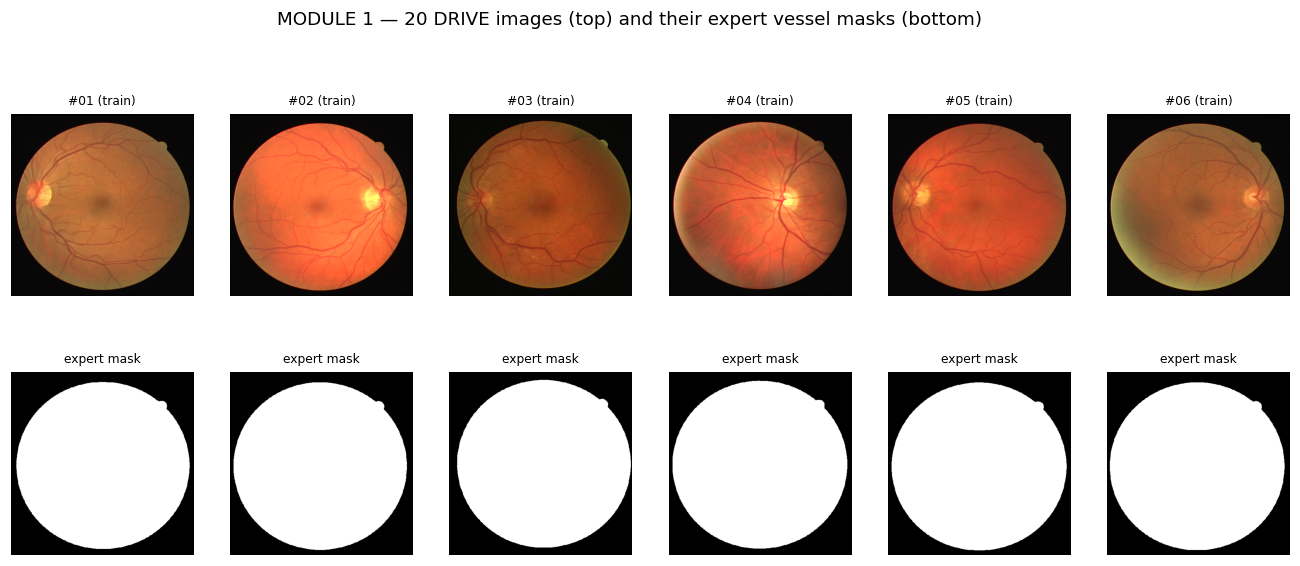

  [saved] results/figures/M1_dataset_samples.png

  RESULT — M1 Data  ::  small DRIVE dataset loaded
  configuration : 20 images @ 512x512 (14 train / 6 test)
  quality value : vessel pixels = 68.77 %, FOV = 100.0 %
  improvement   : 20 images loaded from ZIP dataset (433.8 s load)



In [ ]:


IMG_EXTS = (".tif", ".tiff", ".png", ".jpg", ".jpeg", ".bmp")



GT_TOKENS = {"gt", "label", "labels", "seg", "segs", "segmentation", "vessel", "vessels",

             "truth", "annotation", "annotations"}

FOV_TOKENS = {"roi", "rois", "fov", "field", "fieldofview"}





def _tokens(p: Path) -> set:

    """Path tokens from the parent folder + file stem ('1st_manual/21_manual1' -> manual, manual1)."""

    return set(re.split(r"[^a-z0-9]+", f"{p.parent.name} {p.stem}".lower())) - {""}





def _digits(name: str) -> str:

    """Stable id used to pair an image with its mask ('21_training.tif' -> '21')."""

    groups = [g for g in "".join(c if c.isdigit() else " " for c in Path(name).stem).split() if g]

    return groups[0] if groups else Path(name).stem.lower()





def classify_masks(paths: list) -> tuple:

    """Split mask-like files into (vessel ground truth, field-of-view) — DRIVE naming aware.



    DRIVE ships BOTH '21_manual1.gif' (vessels) and '21_training_mask.gif' (circular FOV);

    picking the wrong one silently scores the model against the retina disk instead of vessels.

    """

    gt_ranked, fov, generic = {}, {}, {}

    for p in paths:

        t, key = _tokens(p), _digits(p.name)

        if t & FOV_TOKENS:

            fov.setdefault(key, p)

        elif "manual1" in t or ("manual" in t and "1st" in t):

            gt_ranked.setdefault(key, []).append((0, p))

        elif "manual2" in t or ("manual" in t and "2nd" in t):

            gt_ranked.setdefault(key, []).append((3, p))

        elif any(x.startswith("manual") for x in t) or (t & GT_TOKENS):

            gt_ranked.setdefault(key, []).append((1, p))

        elif t & {"mask", "masks"}:

            generic.setdefault(key, p)

    gt = {k: min(v, key=lambda r: r[0])[1] for k, v in gt_ranked.items()}

    for key, p in generic.items():



        (fov if key in gt else gt).setdefault(key, p)

    return gt, fov





def _is_mask_path(p: Path) -> bool:

    t = _tokens(p)

    return bool(t & (GT_TOKENS | FOV_TOKENS | {"mask", "masks"})

                or any(x.startswith("manual") for x in t))





def kaggle_download(dest: Path) -> bool:

    """Install the Kaggle CLI, upload kaggle.json, download + unzip a DRIVE mirror."""

    try:

        from google.colab import files

        print(">>> Upload your Kaggle API token (kaggle.json) in the widget below:")

        up = files.upload()

        if not up:

            print("!! no file uploaded")

            return False

        kdir = Path.home() / ".kaggle"

        kdir.mkdir(exist_ok=True)

        for fname, blob in up.items():

            (kdir / "kaggle.json").write_bytes(blob)

        (kdir / "kaggle.json").chmod(0o600)

    except Exception as exc:

        print(f"(not running inside Colab: {type(exc).__name__}; using existing kaggle credentials)")



    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kaggle"], check=False)

    dest.mkdir(parents=True, exist_ok=True)

    for slug in [CONFIG["KAGGLE_DATASET"]] + CONFIG["KAGGLE_FALLBACKS"]:

        print(f">>> trying Kaggle dataset: {slug}")

        r = subprocess.run([sys.executable, "-m", "kaggle", "datasets", "download", "-d", slug,

                            "-p", str(dest), "--unzip"], capture_output=True, text=True)

        if r.returncode == 0:

            print(f"    OK  ({slug})")

            return True

        print(f"    failed: {r.stderr.strip().splitlines()[-1] if r.stderr.strip() else r.stdout[-200:]}")

    return False





def discover_pairs(root: Path) -> pd.DataFrame:

    """Walk a dataset tree of ANY layout and pair images with masks by numeric id."""

    files = [Path(p) for p in glob.glob(f"{root}/**/*", recursive=True) if Path(p).is_file()]

    imgs = [p for p in files if p.suffix.lower() in IMG_EXTS and not _is_mask_path(p)

            and "__MACOSX" not in str(p)]

    mask_like = sorted(p for p in files

                       if p.suffix.lower() in IMG_EXTS + (".gif",) and _is_mask_path(p))

    m_by_id, f_by_id = classify_masks(mask_like)

    rows = []

    for im in sorted(imgs):

        mid = _digits(im.name)

        cand = m_by_id.get(mid)

        if cand is None:

            same = [m for m in mask_like if m.stem.lower().startswith(im.stem.lower()[:2])]

            cand = same[0] if same else None

        if cand is None:

            continue

        split = "test" if any(k in str(im).lower() for k in ("test", "valid")) else "train"

        rows.append({"id": mid, "image": str(im), "mask": str(cand),

                     "fov": str(f_by_id.get(mid, "")), "split": split})

    return pd.DataFrame(rows).drop_duplicates("id").reset_index(drop=True)





def synthetic_drive(dest: Path, n: int = 20, size: int = 565, target_vessel: float = 0.085) -> Path:

    """Phantom fundus generator (offline fallback, no Kaggle account needed).



    Renders at DRIVE's native 565 px then resizes, so the vessel density is resolution

    independent. A branching arcade tree grows from the optic disc and a capillary bed is

    added until the vessel fraction matches DRIVE's 7-12 %.

    """

    rng = np.random.default_rng(CONFIG["SEED"])

    (dest / "training" / "images").mkdir(parents=True, exist_ok=True)

    (dest / "training" / "1st_manual").mkdir(parents=True, exist_ok=True)

    (dest / "training" / "mask").mkdir(parents=True, exist_ok=True)

    R = 565

    yy, xx = np.mgrid[0:R, 0:R]

    cy = cx = R // 2

    fov = ((yy - cy) ** 2 + (xx - cx) ** 2) < (0.44 * R) ** 2



    def branch(mask, x, y, ang, width, depth):

        if depth == 0 or width < 0.7:

            return

        for _ in range(int(rng.integers(25, 55))):

            x2, y2 = x + math.cos(ang), y + math.sin(ang)

            cv2.line(mask, (int(x), int(y)), (int(x2), int(y2)), 255, max(1, int(round(width))))

            ang += rng.normal(0, 0.10)

            x, y = x2, y2

            width *= 0.985

        branch(mask, x, y, ang + rng.uniform(0.5, 1.0), width * 0.74, depth - 1)

        branch(mask, x, y, ang - rng.uniform(0.5, 1.0), width * 0.74, depth - 1)



    def binarise(raw):

        v = (cv2.GaussianBlur(raw, (0, 0), 0.5) > 80).astype(np.uint8) * 255

        v[~fov] = 0

        return v



    for i in range(n):

        raw = np.zeros((R, R), np.uint8)

        disc = (int(cx + rng.uniform(-60, 60)), int(cy + rng.uniform(-60, 60)))

        for k in range(4):

            a = (2 * math.pi * k / 4) + rng.uniform(-0.3, 0.3)

            branch(raw, disc[0] + 45 * math.cos(a), disc[1] + 45 * math.sin(a), a,

                   rng.uniform(5.5, 7.5), 4)

        vessel = binarise(raw)

        for _ in range(90):

            if vessel[fov].mean() / 255.0 >= target_vessel:

                break

            a0, r0 = rng.uniform(0, 2 * math.pi), rng.uniform(30, 0.42 * R)

            branch(raw, cx + r0 * math.cos(a0), cy + r0 * math.sin(a0),

                   rng.uniform(0, 2 * math.pi), rng.uniform(1.6, 3.0), 3)

            vessel = binarise(raw)



        base = np.zeros((R, R, 3), np.float32)

        r = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2) / (0.44 * R)

        base[..., 0], base[..., 1], base[..., 2] = 150 - 45 * r, 70 - 30 * r, 40 - 22 * r

        cv2.circle(base, disc, 42, (245.0, 225.0, 170.0), -1)

        base = cv2.GaussianBlur(base, (0, 0), 6)

        base[vessel > 0] *= 0.55
        base = np.clip(base + rng.normal(0, 3.5, base.shape), 0, 255).astype(np.uint8)



        rs = (size, size)

        Image.fromarray(cv2.resize(base, rs, interpolation=cv2.INTER_AREA)).save(

            dest / "training" / "images" / f"{i+21:02d}_training.tif")

        Image.fromarray(cv2.resize(vessel, rs, interpolation=cv2.INTER_NEAREST)).save(

            dest / "training" / "1st_manual" / f"{i+21:02d}_manual1.gif")

        Image.fromarray(cv2.resize((fov * 255).astype(np.uint8), rs,

                                   interpolation=cv2.INTER_NEAREST)).save(

            dest / "training" / "mask" / f"{i+21:02d}_training_mask.gif")

    return dest





def imread_any(path: str, grayscale: bool = False) -> np.ndarray:

    """PIL-based reader (handles the .gif masks that cv2.imread rejects)."""

    im = Image.open(path)

    if grayscale:

        return np.array(im.convert("L"))

    return np.array(im.convert("RGB"))


t0 = time.time()

from google.colab import files
import zipfile

print("Upload your DRIVE dataset ZIP file.")
uploaded = files.upload()

zip_files = [name for name in uploaded if name.lower().endswith(".zip")]
if not zip_files:
    raise RuntimeError("No .zip file was uploaded. Please upload your dataset ZIP.")

zip_name = zip_files[0]
ZIP_PATH = Path("/content") / zip_name
EXTRACT_DIR = Path("/content/drive_extracted")
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

print(f"ZIP file uploaded: {zip_name}")
print(f"Dataset extracted to: {EXTRACT_DIR}")

ROOT = EXTRACT_DIR
pairs = discover_pairs(ROOT)

if pairs.empty:
    raise RuntimeError(
        f"No image/mask pairs found under {ROOT}. "
        "Check that the ZIP contains retinal images and vessel masks."
    )

n = min(CONFIG["N_IMAGES"], len(pairs))
pairs = pairs.sort_values("id").reset_index(drop=True)
n_tr = max(1, int(round(n * CONFIG["TRAIN_RATIO"])))
pairs = pairs.iloc[:n].copy().reset_index(drop=True)
pairs["split"] = ["train"] * n_tr + ["test"] * (n - n_tr)


S = CONFIG["IMG_SIZE"]

RGB, MSK, FOV = [], [], []

for row in pairs.itertuples():

    rgb = cv2.resize(imread_any(row.image), (S, S), interpolation=cv2.INTER_AREA)

    msk = cv2.resize(imread_any(row.mask, grayscale=True), (S, S), interpolation=cv2.INTER_NEAREST)

    fov = (cv2.resize(imread_any(row.fov, grayscale=True), (S, S), interpolation=cv2.INTER_NEAREST) > 0

           ) if row.fov else np.ones((S, S), bool)

    RGB.append(rgb)

    MSK.append((msk > 127).astype(np.uint8))

    FOV.append(fov)

RGB = np.stack(RGB)

MSK = np.stack(MSK)

FOV = np.stack(FOV)

split = pairs["split"].to_numpy()



dataset_info = pd.DataFrame({

    "attribute": ["source", "root folder", "images loaded", "train / test split",

                  "image size (H x W x C)", "image dtype / range", "vessel pixel fraction (mean)",

                  "FOV coverage (mean)", "load time"],

    "value": ["uploaded ZIP", str(ROOT), len(RGB),

              f"{int((split=='train').sum())} / {int((split=='test').sum())}",

              f"{RGB.shape[1]} x {RGB.shape[2]} x {RGB.shape[3]}",

              f"{RGB.dtype} / 0-255",

              f"{MSK.mean()*100:.2f} %", f"{FOV.mean()*100:.2f} %", f"{time.time()-t0:.2f} s"],

})

save_table(dataset_info, "M1_dataset_info")



fig, ax = plt.subplots(2, 6, figsize=(15, 5.6))

for j in range(6):

    ax[0, j].imshow(RGB[j]); ax[0, j].set_title(f"#{pairs['id'][j]} ({split[j]})", fontsize=8)

    ax[0, j].axis("off")

    ax[1, j].imshow(MSK[j], cmap="gray"); ax[1, j].set_title("expert mask", fontsize=8)

    ax[1, j].axis("off")

fig.suptitle(f"MODULE 1 — {len(RGB)} DRIVE images (top) and their expert vessel masks (bottom)",

             fontsize=12, y=1.02)

save_fig(fig, "M1_dataset_samples")



log_module("M1 Data", "small DRIVE dataset loaded",

           f"{len(RGB)} images @ {S}x{S} ({(split=='train').sum()} train / {(split=='test').sum()} test)",

           f"vessel pixels = {MSK.mean()*100:.2f} %, FOV = {FOV.mean()*100:.1f} %",

           f"{len(RGB)} images loaded from ZIP dataset ({time.time()-t0:.1f} s load)")

---
## MODULE 2 — PRE-PROCESSING & CONTRAST ENHANCEMENT


MODULE 2 — mean image-quality values per enhancement stage (n = 20 images)
                           Mean brightness  Std (σ)  RMS contrast  Michelson contrast  Entropy (bits)  Sharpness (VoL)  Avg gradient (AGC)  Dynamic range (p5–p95)  PSNR (dB)    SSIM
Stage                                                                                                                                                                                
S0 Original (gray)                  0.3294   0.2121        0.2121              0.9993          5.6682           0.0008              0.0093                  0.5237        inf  1.0000
S1 Green channel                    0.2657   0.1719        0.1719              1.0000          5.5319           0.0010              0.0101                  0.4273    22.2347  0.9633
S2 Green + bilateral                0.2658   0.1707        0.1707              0.9992          5.2928           0.0007              0.0055                  0.4224    22.1754  0.9298
S3 + CLAHE (2.

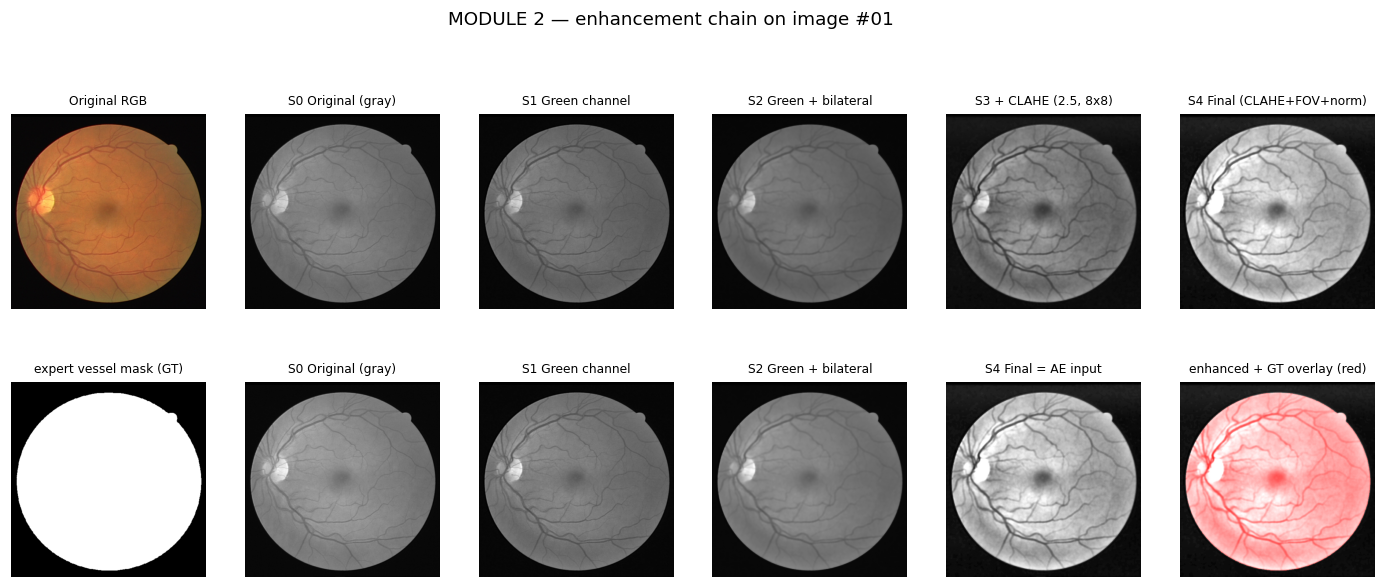

  [saved] results/figures/M2_enhancement_chain.png


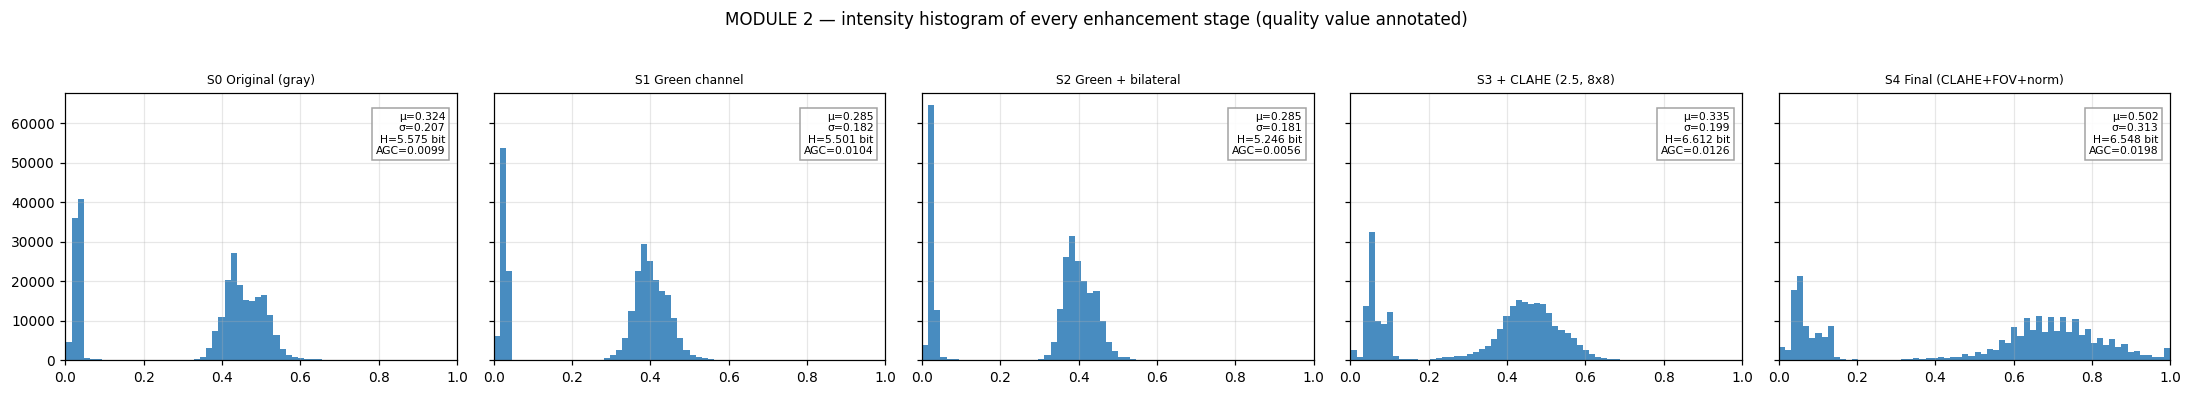

  [saved] results/figures/M2_histograms_per_stage.png


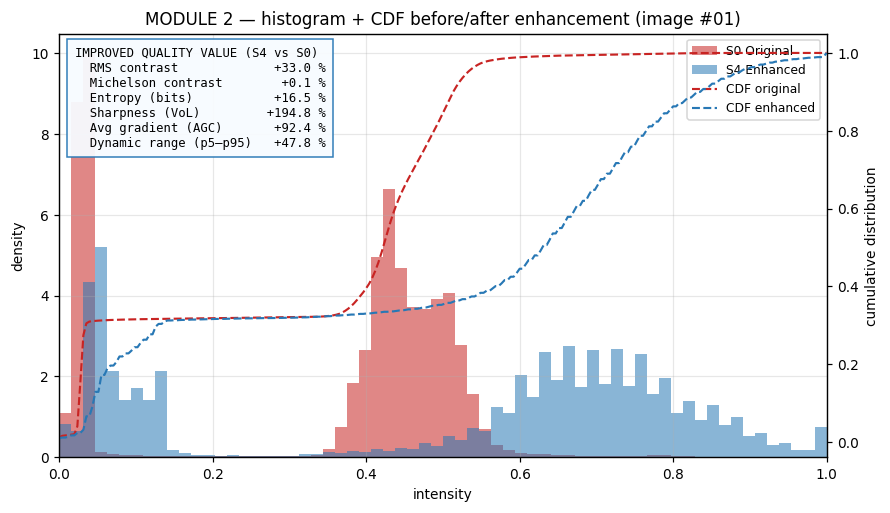

  [saved] results/figures/M2_histogram_before_after.png


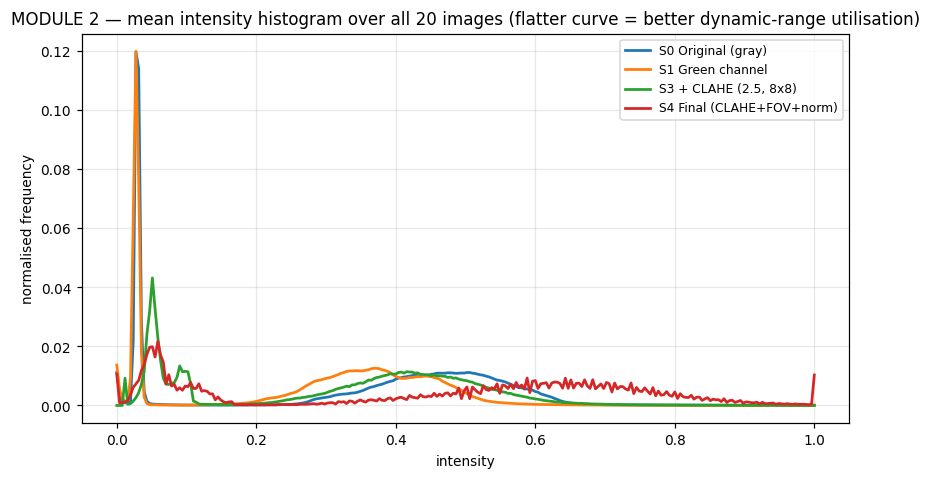

  [saved] results/figures/M2_histogram_dataset_mean.png


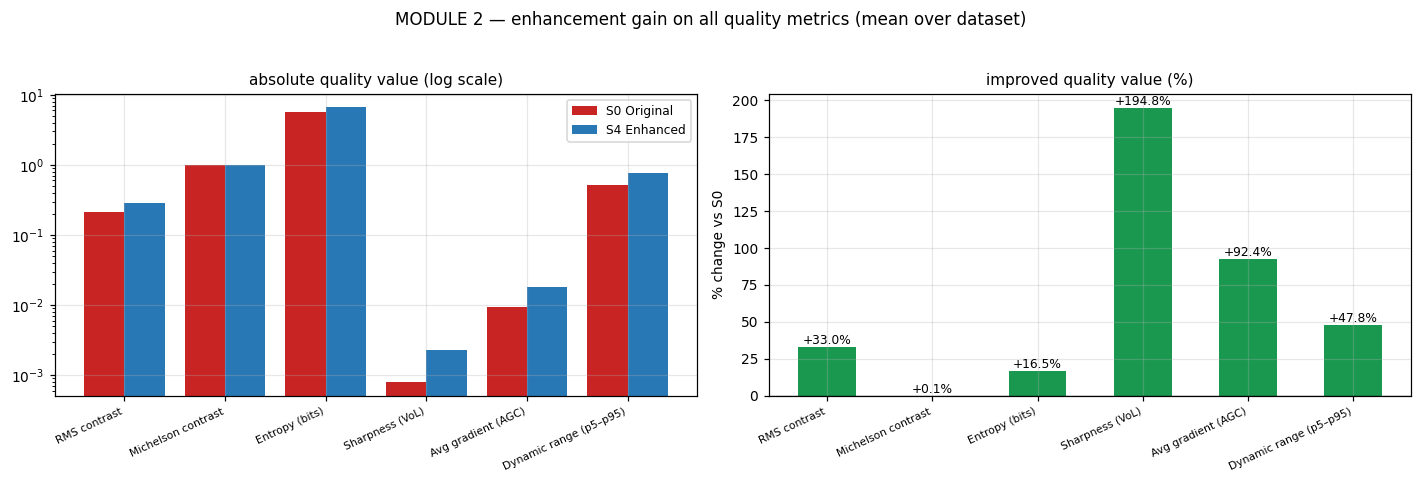

  [saved] results/figures/M2_quality_gain_bars.png

  RESULT — M2 Enhancement  ::  green channel + bilateral + CLAHE + FOV normalisation
  configuration : CLAHE clip=2.5, tile=8x8; bilateral d=7/σ45; 1–99 % min–max
  quality value : entropy 5.668→6.606 bit, AGC 0.0093→0.0179
  improvement   : RMS contrast +33.0 %, entropy +16.5 %, sharpness +194.8 %, AGC +92.4 %



In [ ]:

def to01(a: np.ndarray) -> np.ndarray:
    a = np.asarray(a, np.float32)
    return np.clip(a / 255.0 if a.max() > 1.5 else a, 0, 1)


def gray01(img: np.ndarray) -> np.ndarray:
    g = to01(img)
    return cv2.cvtColor((g * 255).astype(np.uint8), cv2.COLOR_RGB2GRAY).astype(np.float32) / 255 \
        if g.ndim == 3 else g


def enhance_chain(rgb: np.ndarray, fov: np.ndarray) -> dict:
    """Return every enhancement stage as float 0..1 (single channel)."""
    g = rgb[..., 1].astype(np.float32)
    den = cv2.bilateralFilter(g.astype(np.uint8), d=7, sigmaColor=45,
                              sigmaSpace=45).astype(np.float32)
    cl = clahe.apply(den.astype(np.uint8)).astype(np.float32)
    fin = np.zeros_like(cl)
    reg = cl[fov] if fov.any() else cl
    lo, hi = np.percentile(reg, [1, 99])
    fin[fov] = np.clip((cl[fov] - lo) / max(hi - lo, 1e-6), 0, 1)
    return {"S0 Original (gray)": gray01(rgb), "S1 Green channel": to01(g),
            "S2 Green + bilateral": to01(den), "S3 + CLAHE (2.5, 8x8)": to01(cl),
            "S4 Final (CLAHE+FOV+norm)": fin}


def quality_metrics(img: np.ndarray, ref: np.ndarray | None = None, mask: np.ndarray | None = None
                    ) -> dict:
    """8 no-reference quality values (+ PSNR/SSIM when a reference is given).

    All statistics are computed INSIDE the field of view so that the black surround of the
    FOV-masked stage cannot distort entropy / gradient measures.
    """
    x = gray01(img)
    m = np.ones_like(x, bool) if mask is None else mask.astype(bool)
    v = x[m]
    mu, sd = float(v.mean()), float(v.std())
    gy, gx = np.gradient(x)
    lap = cv2.Laplacian(x, cv2.CV_32F)
    hist, _ = np.histogram(v, bins=256, range=(0, 1))
    pr = hist / max(hist.sum(), 1)
    pr = pr[pr > 0]
    p5, p95 = (float(t) for t in np.percentile(v, [5, 95]))
    out = {
        "Mean brightness": mu,
        "Std (σ)": sd,
        "RMS contrast": float(np.sqrt(((v - mu) ** 2).mean())),
        "Michelson contrast": float((v.max() - v.min()) / (v.max() + v.min() + 1e-8)),
        "Entropy (bits)": float(-(pr * np.log2(pr)).sum()),
        "Sharpness (VoL)": float((lap[m] ** 2).mean()),
        "Avg gradient (AGC)": float(np.sqrt(gx ** 2 + gy ** 2)[m].mean()),
        "Dynamic range (p5–p95)": p95 - p5,
    }
    if ref is not None:
        r = gray01(ref)
        out["PSNR (dB)"] = float(peak_signal_noise_ratio(r, x, data_range=1.0))
        out["SSIM"] = float(structural_similarity(r, x, data_range=1.0))
    return out


NR_METRICS = ["Mean brightness", "Std (σ)", "RMS contrast", "Michelson contrast", "Entropy (bits)",
              "Sharpness (VoL)", "Avg gradient (AGC)", "Dynamic range (p5–p95)"]

stages = [enhance_chain(RGB[i], FOV[i]) for i in range(len(RGB))]
STAGE_NAMES = list(stages[0].keys())
ENH = np.stack([s[STAGE_NAMES[-1]] for s in stages])
assert ENH.shape == (len(RGB), S, S)

rows = []
for st in STAGE_NAMES:
    per = [quality_metrics(s[st], ref=s[STAGE_NAMES[0]], mask=FOV[i])
           for i, s in enumerate(stages)]
    row = {"Stage": st}
    for k in per[0]:
        row[k] = float(np.mean([d[k] for d in per]))
    rows.append(row)
q = pd.DataFrame(rows).set_index("Stage")

base = q.loc[STAGE_NAMES[0]]
imp = pd.DataFrame({
    "Metric": NR_METRICS,
    "S0 Original": base[NR_METRICS].values,
    "S4 Enhanced (final)": q.loc[STAGE_NAMES[-1], NR_METRICS].values,
})
imp["Absolute gain"] = imp["S4 Enhanced (final)"] - imp["S0 Original"]
imp["Improved quality value (%)"] = 100.0 * imp["Absolute gain"] / (imp["S0 Original"].abs() + 1e-12)
imp = imp.round(4)
print("\nMODULE 2 — mean image-quality values per enhancement stage (n = %d images)" % len(RGB))
print(q.round(4).to_string())
print("\nMODULE 2 — ORIGINAL vs ENHANCED  (improved quality value)")
print(imp.to_string(index=False))
save_table(q.reset_index(), "M2_quality_per_stage")
save_table(imp, "M2_enhancement_improvement")

# ------------------------------------------------------------------ Fig 2a: pipeline ------------
k = 0
fig, ax = plt.subplots(2, 6, figsize=(16, 5.8))
ax[0, 0].imshow(RGB[k]); ax[0, 0].set_title("Original RGB", fontsize=8)
for j, st in enumerate(STAGE_NAMES):
    ax[0, j + 1].imshow(stages[k][st], cmap="gray", vmin=0, vmax=1)
    ax[0, j + 1].set_title(st, fontsize=8)
ax[1, 0].imshow(MSK[k], cmap="gray"); ax[1, 0].set_title("expert vessel mask (GT)", fontsize=8)
for j, st in enumerate(STAGE_NAMES[:3]):
    ax[1, j + 1].imshow(stages[k][st], cmap="gray"); ax[1, j + 1].set_title(st, fontsize=8)
ax[1, 4].imshow(ENH[k], cmap="gray"); ax[1, 4].set_title("S4 Final = AE input", fontsize=8)
ov = np.stack([ENH[k]] * 3, -1); ov[..., 0] = np.maximum(ov[..., 0], MSK[k])
ax[1, 5].imshow(ov); ax[1, 5].set_title("enhanced + GT overlay (red)", fontsize=8)
for a in ax.ravel():
    a.axis("off")
fig.suptitle(f"MODULE 2 — enhancement chain on image #{pairs['id'][k]}", fontsize=12, y=1.02)
save_fig(fig, "M2_enhancement_chain")

fig, ax = plt.subplots(1, len(STAGE_NAMES), figsize=(4 * len(STAGE_NAMES), 3.4), sharey=True)
for a, st in zip(ax, STAGE_NAMES):
    m = quality_metrics(stages[k][st])
    a.hist(stages[k][st].ravel(), bins=64, range=(0, 1), color="#2878b5", alpha=.85)
    a.set_title(st, fontsize=8)
    a.text(.97, .93, f"μ={m['Mean brightness']:.3f}\nσ={m['Std (σ)']:.3f}\n"
                     f"H={m['Entropy (bits)']:.3f} bit\nAGC={m['Avg gradient (AGC)']:.4f}",
           transform=a.transAxes, ha="right", va="top", fontsize=7,
           bbox=dict(fc="w", ec="#999", alpha=.9, pad=2.5))
    a.set_xlim(0, 1)
fig.suptitle("MODULE 2 — intensity histogram of every enhancement stage (quality value annotated)",
             fontsize=11, y=1.04)
fig.tight_layout()
save_fig(fig, "M2_histograms_per_stage")
fig, ax = plt.subplots(figsize=(9, 5))
ov, ev = stages[k][STAGE_NAMES[0]][FOV[k]], ENH[k][FOV[k]]
ax.hist(ov, bins=64, range=(0, 1), alpha=.55, color="#c82423", label="S0 Original", density=True)
ax.hist(ev, bins=64, range=(0, 1), alpha=.55, color="#2878b5", label="S4 Enhanced", density=True)
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(np.linspace(0, 1, 256), np.cumsum(np.histogram(ov, 256, (0, 1))[0]) / ov.size,
         "--", color="#c82423", lw=1.4, label="CDF original")
ax2.plot(np.linspace(0, 1, 256), np.cumsum(np.histogram(ev, 256, (0, 1))[0]) / ev.size,
         "--", color="#2878b5", lw=1.4, label="CDF enhanced")
ax2.set_ylabel("cumulative distribution")
gains = imp.set_index("Metric")["Improved quality value (%)"]
txt = ("IMPROVED QUALITY VALUE (S4 vs S0)\n"
       + "\n".join(f"  {m:22s} {gains[m]:+7.1f} %" for m in
                   ["RMS contrast", "Michelson contrast", "Entropy (bits)",
                    "Sharpness (VoL)", "Avg gradient (AGC)", "Dynamic range (p5–p95)"]))
ax.text(.02, .97, txt, transform=ax.transAxes, va="top", fontsize=8, family="monospace",
        bbox=dict(fc="#f7fbff", ec="#2878b5", alpha=.95, pad=5))
ax.set_xlabel("intensity"); ax.set_ylabel("density"); ax.set_xlim(0, 1)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8)
ax.set_title(f"MODULE 2 — histogram + CDF before/after enhancement (image #{pairs['id'][k]})", fontsize=11)
save_fig(fig, "M2_histogram_before_after")

fig, ax = plt.subplots(figsize=(9, 4.6))
mean_hist = {}
for st in [STAGE_NAMES[0], "S1 Green channel", "S3 + CLAHE (2.5, 8x8)", STAGE_NAMES[-1]]:
    acc = np.zeros(256)
    for s, i in zip(stages, range(len(stages))):
        acc += np.histogram(s[st][FOV[i]], bins=256, range=(0, 1))[0]
    mean_hist[st] = acc / acc.sum()
    ax.plot(np.linspace(0, 1, 256), mean_hist[st], lw=1.8, label=st)
ax.set_title(f"MODULE 2 — mean intensity histogram over all {len(RGB)} images (flatter curve = "
             "better dynamic-range utilisation)", fontsize=11)
ax.set_xlabel("intensity"); ax.set_ylabel("normalised frequency"); ax.legend(fontsize=8)
save_fig(fig, "M2_histogram_dataset_mean")

sel = ["RMS contrast", "Michelson contrast", "Entropy (bits)", "Sharpness (VoL)",
       "Avg gradient (AGC)", "Dynamic range (p5–p95)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(sel))
ax[0].bar(x - .2, imp.set_index("Metric").loc[sel, "S0 Original"], .4, label="S0 Original", color="#c82423")
ax[0].bar(x + .2, imp.set_index("Metric").loc[sel, "S4 Enhanced (final)"], .4,
          label="S4 Enhanced", color="#2878b5")
ax[0].set_yscale("log"); ax[0].set_xticks(x); ax[0].set_xticklabels(sel, rotation=25, ha="right", fontsize=7)
ax[0].set_title("absolute quality value (log scale)", fontsize=10); ax[0].legend(fontsize=8)
gp = imp.set_index("Metric").loc[sel, "Improved quality value (%)"]
cols = ["#1a9850" if v >= 0 else "#d73027" for v in gp]
ax[1].bar(x, gp, .55, color=cols)
for xi, v in zip(x, gp):
    ax[1].text(xi, v, f"{v:+.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=8)
ax[1].axhline(0, color="k", lw=.8)
ax[1].set_xticks(x); ax[1].set_xticklabels(sel, rotation=25, ha="right", fontsize=7)
ax[1].set_title("improved quality value (%)", fontsize=10); ax[1].set_ylabel("% change vs S0")
fig.suptitle("MODULE 2 — enhancement gain on all quality metrics (mean over dataset)", fontsize=11, y=1.03)
fig.tight_layout()
save_fig(fig, "M2_quality_gain_bars")

best = imp.set_index("Metric")["Improved quality value (%)"]
log_module("M2 Enhancement", "green channel + bilateral + CLAHE + FOV normalisation",
           "CLAHE clip=2.5, tile=8x8; bilateral d=7/σ45; 1–99 % min–max",
           (f"entropy {base['Entropy (bits)']:.3f}→{q.loc[STAGE_NAMES[-1],'Entropy (bits)']:.3f} bit, "
            f"AGC {base['Avg gradient (AGC)']:.4f}→{q.loc[STAGE_NAMES[-1],'Avg gradient (AGC)']:.4f}"),
           (f"RMS contrast {best['RMS contrast']:+.1f} %, entropy {best['Entropy (bits)']:+.1f} %, "
            f"sharpness {best['Sharpness (VoL)']:+.1f} %, AGC {best['Avg gradient (AGC)']:+.1f} %"))

---
## MODULE 3 — PATCH EXTRACTION

  [saved] results/tables/M3_patch_stats.csv
                                item         value
                          patch size       128×128
                              stride            64
              tiles per image (grid)            49
      available tiles (train images)           686
       available tiles (test images)           294
               sampled train patches           686
                 sampled val patches           294
    train patches containing vessels       100.0 %
mean vessel fraction (train patches)       87.23 %
                   batches per epoch            21
                  input tensor shape (1, 128, 128)


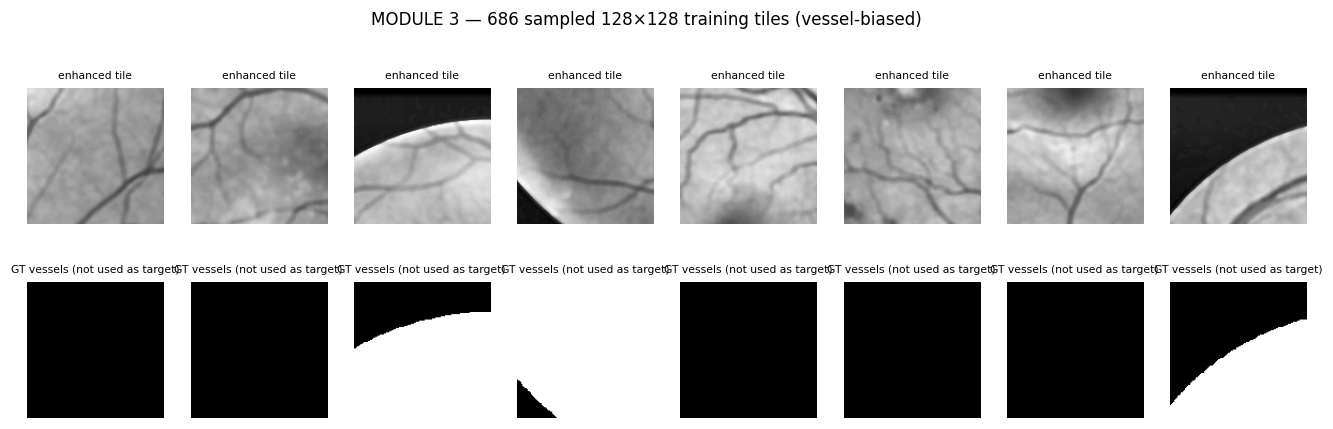

  [saved] results/figures/M3_patch_montage.png

  RESULT — M3 Patches  ::  sliding-window tiling 128×128, stride 64, vessel-biased sampling
  configuration : 686 available train tiles → 686 used; 294 val tiles
  quality value : 100.0 % of training tiles contain vessels
  improvement   : effective training set enlarged 34× vs 20 images



In [ ]:

P, ST = CONFIG["PATCH"], CONFIG["PATCH_STRIDE"]


def sliding_windows(img, msk, fov, patch=P, stride=ST):
    out_i, out_m, out_v = [], [], []
    for y in range(0, S - patch + 1, stride):
        for x in range(0, S - patch + 1, stride):
            sl = (slice(y, y + patch), slice(x, x + patch))
            if fov[sl].mean() < 0.55:
                continue
            out_i.append(img[sl]); out_m.append(msk[sl]); out_v.append(float(msk[sl].mean()))
    return np.stack(out_i), np.stack(out_m), np.array(out_v, np.float32)


tr_i, tr_m, tr_v, va_i, va_m, va_v = [], [], [], [], [], []
for i in range(len(RGB)):
    pi, pm, pv = sliding_windows(ENH[i], MSK[i], FOV[i])
    if split[i] == "train":
        tr_i.append(pi); tr_m.append(pm); tr_v.append(pv)
    else:
        va_i.append(pi); va_m.append(pm); va_v.append(pv)
tr_i, tr_m, tr_v = np.concatenate(tr_i), np.concatenate(tr_m), np.concatenate(tr_v)
va_i, va_m, va_v = np.concatenate(va_i), np.concatenate(va_m), np.concatenate(va_v)

rng = np.random.default_rng(CONFIG["SEED"])


def biased_pick(n_pool, n_want, ves_frac, seed_rng):

    w = w / w.sum()
    return seed_rng.choice(n_pool, size=min(n_want, n_pool), replace=n_pool < n_want, p=w)


TR_IDX = biased_pick(len(tr_i), CONFIG["N_PATCHES_TRAIN"], tr_v, rng)
VA_IDX = biased_pick(len(va_i), CONFIG["N_PATCHES_VAL"], va_v, rng)


class PatchAE(Dataset):
    """Self-supervised: input == target (the enhanced tile)."""

    def __init__(self, imgs, idx, augment=False):
        self.x = imgs[idx].astype(np.float32)[:, None]
        self.augment = augment

    def __len__(self):
        return len(self.x)

    def __getitem__(self, i):
        a = self.x[i]
        if self.augment:
            k = int(np.random.randint(4))
            a = np.rot90(a, k, axes=(1, 2)).copy()
            if np.random.rand() > .5:
                a = a[..., ::-1].copy()
            if np.random.rand() > .5:
                a = a[:, ::-1].copy()
            if np.random.rand() > .7:
                a = np.clip(a + np.random.normal(0, .02, a.shape), 0, 1).astype(np.float32)
        return torch.from_numpy(a.copy()), torch.from_numpy(a.copy())


train_ds = PatchAE(tr_i, TR_IDX, augment=True)
val_ds = PatchAE(va_i, VA_IDX, augment=False)
DROP_LAST = len(train_ds) >= CONFIG["BATCH"]
train_dl = DataLoader(train_ds, batch_size=CONFIG["BATCH"], shuffle=True,
                      num_workers=0, pin_memory=(DEVICE.type == "cuda"), drop_last=DROP_LAST)
val_dl = DataLoader(val_ds, batch_size=CONFIG["BATCH"], shuffle=False, num_workers=0)

patch_stats = pd.DataFrame({
    "item": ["patch size", "stride", "tiles per image (grid)", "available tiles (train images)",
             "available tiles (test images)", "sampled train patches", "sampled val patches",
             "train patches containing vessels", "mean vessel fraction (train patches)",
             "batches per epoch", "input tensor shape"],
    "value": [f"{P}×{P}", ST, len(range(0, S - P + 1, ST)) ** 2, len(tr_i), len(va_i),
              len(train_ds), len(val_ds), f"{(tr_v[TR_IDX] > 0).mean()*100:.1f} %",
              f"{tr_v[TR_IDX].mean()*100:.2f} %", len(train_dl), str(tuple(train_ds[0][0].shape))],
})
save_table(patch_stats, "M3_patch_stats")
print(patch_stats.to_string(index=False))

n_show = min(8, len(train_ds))
fig, ax = plt.subplots(2, n_show, figsize=(15, 4.2))
for j in range(n_show):
    ax[0, j].imshow(train_ds.x[j][0], cmap="gray", vmin=0, vmax=1)
    ax[0, j].set_title("enhanced tile", fontsize=7)
    ax[1, j].imshow(tr_m[TR_IDX[j]], cmap="gray")
    ax[1, j].set_title("GT vessels (not used as target)", fontsize=7)
for a in ax.ravel():
    a.axis("off")
fig.suptitle(f"MODULE 3 — {len(train_ds)} sampled {P}×{P} training tiles (vessel-biased)", fontsize=11, y=1.02)
save_fig(fig, "M3_patch_montage")

log_module("M3 Patches", f"sliding-window tiling {P}×{P}, stride {ST}, vessel-biased sampling",
           f"{len(tr_i)} available train tiles → {len(train_ds)} used; {len(val_ds)} val tiles",
           f"{(tr_v[TR_IDX]>0).mean()*100:.1f} % of training tiles contain vessels",
           f"effective training set enlarged {len(train_ds)/max(len(RGB),1):.0f}× vs {len(RGB)} images")

---
## MODULE 4 — CONVOLUTIONAL AUTOENCODER


MODULE 4 — CONVOLUTIONAL AUTOENCODER LAYER TABLE (layout · filters · activation)
 #       Block           Layer Layout (kernel · stride · pad) Filters (in → out) Activation Output C×H×W  Params
 1   Encoder-1          Conv2d             K3×3 · s1×1 · p1×1             1 → 32       ReLU   32×128×128     288
 2   Encoder-1     BatchNorm2d       1×1 (per-channel affine)                 32        n/a   32×128×128      64
 3   Encoder-1      Activation                   element-wise                  –       ReLU   32×128×128       0
 4   Encoder-1          Conv2d             K3×3 · s1×1 · p1×1            32 → 32       ReLU   32×128×128    9216
 5   Encoder-1     BatchNorm2d       1×1 (per-channel affine)                 32        n/a   32×128×128      64
 6   Encoder-1      Activation                   element-wise                  –       ReLU   32×128×128       0
 7   Encoder-1       MaxPool2d                        K2 · s2                  –        n/a     32×64×64       0
 8   Encoder-2

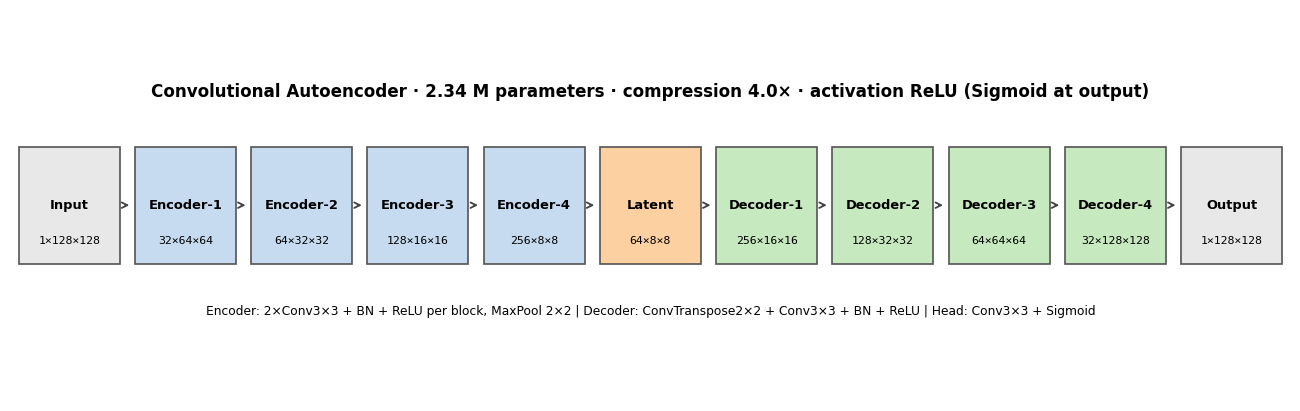

  [saved] results/figures/M4_architecture_diagram.png

  RESULT — M4 Model  ::  symmetric Conv-AE, depth 4, base 32
  configuration : latent 64×8×8, ReLU + Sigmoid
  quality value : 2,342,881 parameters, 49 layers
  improvement   : 4.00× spatial-compression of the input representation


MODULE 4 completed successfully.


In [ ]:

import torch
import torch.nn as nn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


ACT = {
    "ReLU": lambda: nn.ReLU(inplace=True),
    "LeakyReLU": lambda: nn.LeakyReLU(0.1, inplace=True),
    "Sigmoid": lambda: nn.Sigmoid()
}


def _fmt(t):
    if isinstance(t, (tuple, list)):
        return "×".join(str(v) for v in t)
    return str(t)



class ConvAutoencoder(nn.Module):
    """Spec-driven symmetric CNN autoencoder that records its own layer table."""

    def __init__(self, in_ch=1, base=32, latent=64, depth=4, act="ReLU"):
        super().__init__()

        if act not in ACT:
            raise ValueError(
                f"Unsupported activation: {act}. Choose from {list(ACT.keys())}."
            )

        if depth < 1:
            raise ValueError("depth must be at least 1.")

        self.spec = {
            "act": act,
            "base": base,
            "latent": latent,
            "depth": depth
        }
        self.registry = []

        widths = [base * (2 ** i) for i in range(depth)]

        self.enc = nn.ModuleList()
        self.pool = nn.ModuleList()
        self.up = nn.ModuleList()
        self.dec = nn.ModuleList()

        cin = in_ch

        for i, cout in enumerate(widths, start=1):
            b = nn.ModuleDict()

            b["conv1"] = self._reg(
                nn.Conv2d(cin, cout, kernel_size=3, stride=1, padding=1, bias=False),
                f"Encoder-{i}", "Conv2d", act
            )
            b["bn1"] = self._reg(
                nn.BatchNorm2d(cout),
                f"Encoder-{i}", "BatchNorm2d", "n/a"
            )
            b["act1"] = self._reg(
                ACT[act](),
                f"Encoder-{i}", "Activation", act
            )

            b["conv2"] = self._reg(
                nn.Conv2d(cout, cout, kernel_size=3, stride=1, padding=1, bias=False),
                f"Encoder-{i}", "Conv2d", act
            )
            b["bn2"] = self._reg(
                nn.BatchNorm2d(cout),
                f"Encoder-{i}", "BatchNorm2d", "n/a"
            )
            b["act2"] = self._reg(
                ACT[act](),
                f"Encoder-{i}", "Activation", act
            )

            self.enc.append(b)

            self.pool.append(
                self._reg(
                    nn.MaxPool2d(kernel_size=2, stride=2),
                    f"Encoder-{i}", "MaxPool2d", "n/a"
                )
            )

            cin = cout
\
        self.bneck = nn.ModuleDict()

        self.bneck["conv"] = self._reg(
            nn.Conv2d(cin, latent, kernel_size=3, stride=1, padding=1, bias=False),
            "Bottleneck", "Conv2d", act
        )
        self.bneck["bn"] = self._reg(
            nn.BatchNorm2d(latent),
            "Bottleneck", "BatchNorm2d", "n/a"
        )
        self.bneck["act"] = self._reg(
            ACT[act](),
            "Bottleneck", "Activation", act
        )


        dwidths = list(reversed(widths))
        cin = latent

        for i, cout in enumerate(dwidths, start=1):
            b = nn.ModuleDict()

            b["up"] = self._reg(
                nn.ConvTranspose2d(
                    cin, cout, kernel_size=2, stride=2
                ),
                f"Decoder-{i}", "ConvTranspose2d", "n/a"
            )

            b["conv"] = self._reg(
                nn.Conv2d(
                    cout, cout, kernel_size=3, stride=1, padding=1, bias=False
                ),
                f"Decoder-{i}", "Conv2d", act
            )
            b["bn"] = self._reg(
                nn.BatchNorm2d(cout),
                f"Decoder-{i}", "BatchNorm2d", "n/a"
            )
            b["act"] = self._reg(
                ACT[act](),
                f"Decoder-{i}", "Activation", act
            )

            self.dec.append(b)
            cin = cout


        self.head = self._reg(
            nn.Conv2d(cin, in_ch, kernel_size=3, stride=1, padding=1),
            "Output head", "Conv2d", "Sigmoid"
        )

        self.out_act = self._reg(
            nn.Sigmoid(),
            "Output head", "Activation", "Sigmoid"
        )



    def _reg(self, module, block, layer, act):
        self.registry.append({
            "block": block,
            "layer": layer,
            "activation": act,
            "module": module
        })
        return module


    def encode(self, x):
        for b, p in zip(self.enc, self.pool):
            x = b["conv1"](x)
            x = b["bn1"](x)
            x = b["act1"](x)

            x = b["conv2"](x)
            x = b["bn2"](x)
            x = b["act2"](x)

            x = p(x)

        x = self.bneck["conv"](x)
        x = self.bneck["bn"](x)
        x = self.bneck["act"](x)

        return x


    def decode(self, z):
        x = z

        for b in self.dec:
            x = b["up"](x)
            x = b["conv"](x)
            x = b["bn"](x)
            x = b["act"](x)

        x = self.head(x)
        x = self.out_act(x)

        return x


    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)


def architecture_table(model: ConvAutoencoder, shape) -> pd.DataFrame:
    """Generate a layer-wise table including layout, filters, shapes and parameters."""

    shapes = {}

    def hook(mod, _inp, out):
        if torch.is_tensor(out):
            shapes[id(mod)] = tuple(out.shape[1:])

    hs = [
        r["module"].register_forward_hook(hook)
        for r in model.registry
    ]

    device = next(model.parameters()).device
    was_training = model.training
    model.eval()

    try:
        with torch.no_grad():
            dummy = torch.zeros(1, *shape, device=device)
            model(dummy)
    finally:
        for h in hs:
            h.remove()

        model.train(was_training)

    rows = []

    for idx, r in enumerate(model.registry, start=1):
        m = r["module"]

        if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
            layout = (
                f"K{_fmt(m.kernel_size)} · "
                f"s{_fmt(m.stride)} · "
                f"p{_fmt(m.padding)}"
            )
            flt = f"{m.in_channels} → {m.out_channels}"

        elif isinstance(m, nn.MaxPool2d):
            layout = (
                f"K{_fmt(m.kernel_size)} · "
                f"s{_fmt(m.stride)}"
            )
            flt = "–"

        elif isinstance(m, nn.BatchNorm2d):
            layout = "1×1 (per-channel affine)"
            flt = str(m.num_features)

        else:
            layout = "element-wise"
            flt = "–"

        rows.append({
            "#": str(idx),
            "Block": r["block"],
            "Layer": r["layer"],
            "Layout (kernel · stride · pad)": layout,
            "Filters (in → out)": flt,
            "Activation": r["activation"],
            "Output C×H×W": "×".join(
                str(v) for v in shapes.get(id(m), ())
            ),
            "Params": sum(p.numel() for p in m.parameters())
        })

    return pd.DataFrame(rows)

]
if P % (2 ** CONFIG["DEPTH"]) != 0:
    raise ValueError(
        f"P={P} must be divisible by 2**DEPTH "
        f"({2 ** CONFIG['DEPTH']}) for this symmetric autoencoder. "
        "Change P or DEPTH in CONFIG."

DEVICE = torch.device(
    DEVICE if isinstance(DEVICE, str) else DEVICE
)

model = ConvAutoencoder(
    in_ch=1,
    base=CONFIG["BASE_CH"],
    latent=CONFIG["LATENT_CH"],
    depth=CONFIG["DEPTH"],
    act="ReLU"
).to(DEVICE)

dummy = torch.zeros(1, 1, P, P, device=DEVICE)

with torch.no_grad():
    Z = model.encode(dummy)


arch = architecture_table(model, (1, P, P))


total = sum(p.numel() for p in model.parameters())
trainable = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

in_dim = P * P
lat_dim = int(np.prod(Z.shape[1:]))

if lat_dim == 0:
    raise ValueError("Latent dimension is zero. Check P and DEPTH.")

compression = in_dim / lat_dim



total_row = pd.DataFrame([{
    "#": "—",
    "Block": "TOTAL",
    "Layer": f"{len(arch)} layers",
    "Layout (kernel · stride · pad)": (
        f"input 1×{P}×{P} → latent "
        f"{Z.shape[1]}×{Z.shape[2]}×{Z.shape[3]}"
    ),
    "Filters (in → out)": f"compression {compression:.1f}×",
    "Activation": "–",
    "Output C×H×W": f"1×{P}×{P}",
    "Params": total
}])

arch_total = pd.concat(
    [arch, total_row],
    ignore_index=True
)


print(
    "\nMODULE 4 — CONVOLUTIONAL AUTOENCODER "
    "LAYER TABLE (layout · filters · activation)"
)
print(arch.to_string(index=False))

print(f"\n  total parameters : {total:,} (trainable {trainable:,})")
print(f"  latent code      : {tuple(Z.shape)} = {lat_dim:,} values")
print(f"  compression      : {in_dim:,} → {lat_dim:,} = {compression:.2f}×")


save_table(arch_total, "M4_architecture_table")


fig, ax = plt.subplots(figsize=(15, 4.6))
ax.axis("off")

blocks = [
    ("Input", f"1×{P}×{P}", "#e8e8e8")
]

for r in model.registry:
    if r["layer"] == "MaxPool2d":
        row = arch.loc[
            (arch["Block"] == r["block"]) &
            (arch["Layer"] == r["layer"])
        ]

        if not row.empty:
            blocks.append((
                r["block"],
                row.iloc[0]["Output C×H×W"],
                "#c6dbef"
            ))

blocks.append((
    "Latent",
    "×".join(str(v) for v in Z.shape[1:]),
    "#fdd0a2"
))

for r in model.registry:
    if r["layer"] == "ConvTranspose2d":
        row = arch.loc[
            (arch["Block"] == r["block"]) &
            (arch["Layer"] == r["layer"])
        ]

        if not row.empty:
            blocks.append((
                r["block"],
                row.iloc[0]["Output C×H×W"],
                "#c7e9c0"
            ))

blocks.append((
    "Output",
    f"1×{P}×{P}",
    "#e8e8e8"
))

w = 1.0 / len(blocks)

for i, (nm, shp, col) in enumerate(blocks):
    x0 = i * w + 0.006

    ax.add_patch(
        plt.Rectangle(
            (x0, 0.35),
            w - 0.012,
            0.30,
            facecolor=col,
            edgecolor="#555",
            linewidth=1.1
        )
    )

    ax.text(
        i * w + w / 2,
        0.50,
        nm,
        ha="center",
        va="center",
        fontsize=8.5,
        weight="bold"
    )

    ax.text(
        i * w + w / 2,
        0.41,
        shp,
        ha="center",
        va="center",
        fontsize=7.5,
        family="monospace"
    )

    if i > 0:
        ax.annotate(
            "",
            xy=(i * w + 0.004, 0.50),
            xytext=(i * w - 0.004, 0.50),
            arrowprops=dict(
                arrowstyle="->",
                linewidth=1.2,
                color="#444"
            )
        )

ax.text(
    0.5,
    0.78,
    f"Convolutional Autoencoder · {total / 1e6:.2f} M parameters · "
    f"compression {compression:.1f}× · "
    "activation ReLU (Sigmoid at output)",
    ha="center",
    fontsize=11,
    weight="bold"
)

ax.text(
    0.5,
    0.22,
    "Encoder: 2×Conv3×3 + BN + ReLU per block, MaxPool 2×2 | "
    "Decoder: ConvTranspose2×2 + Conv3×3 + BN + ReLU | "
    "Head: Conv3×3 + Sigmoid",
    ha="center",
    fontsize=8
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

save_fig(fig, "M4_architecture_diagram")
plt.show()
plt.close(fig)



log_module(
    "M4 Model",
    f"symmetric Conv-AE, depth {CONFIG['DEPTH']}, "
    f"base {CONFIG['BASE_CH']}",
    f"latent {Z.shape[1]}×{Z.shape[2]}×{Z.shape[3]}, ReLU + Sigmoid",
    f"{total:,} parameters, {len(arch)} layers",
    f"{compression:.2f}× spatial-compression of the input representation"
)

print("\nMODULE 4 completed successfully.")


---
## MODULE 5 — TRAINING

training on cuda · 686 patches · 21 batches/epoch · 100 epochs · batch 32

  epoch   1/100 | train 0.11784 | val 0.11892 | PSNR 13.53 dB | SSIM 0.4954 | lr 1.00e-03   *best*
  epoch   2/100 | train 0.09371 | val 0.08497 | PSNR 16.92 dB | SSIM 0.5197 | lr 1.00e-03   *best*
  epoch   4/100 | train 0.05808 | val 0.05298 | PSNR 20.56 dB | SSIM 0.6413 | lr 9.98e-04   *best*
  epoch   6/100 | train 0.04631 | val 0.05016 | PSNR 19.77 dB | SSIM 0.6940 | lr 9.94e-04   *best*
  epoch   7/100 | train 0.04296 | val 0.03500 | PSNR 24.99 dB | SSIM 0.7400 | lr 9.91e-04   *best*
  epoch  10/100 | train 0.03281 | val 0.02550 | PSNR 27.40 dB | SSIM 0.8061 | lr 9.80e-04   *best*
  epoch  13/100 | train 0.03071 | val 0.02423 | PSNR 26.78 dB | SSIM 0.8194 | lr 9.65e-04   *best*
  epoch  16/100 | train 0.02668 | val 0.02311 | PSNR 27.48 dB | SSIM 0.8330 | lr 9.46e-04   *best*
  epoch  18/100 | train 0.02580 | val 0.02310 | PSNR 27.24 dB | SSIM 0.8322 | lr 9.30e-04   *best*
  epoch  19/100 | train 0.02461 | 

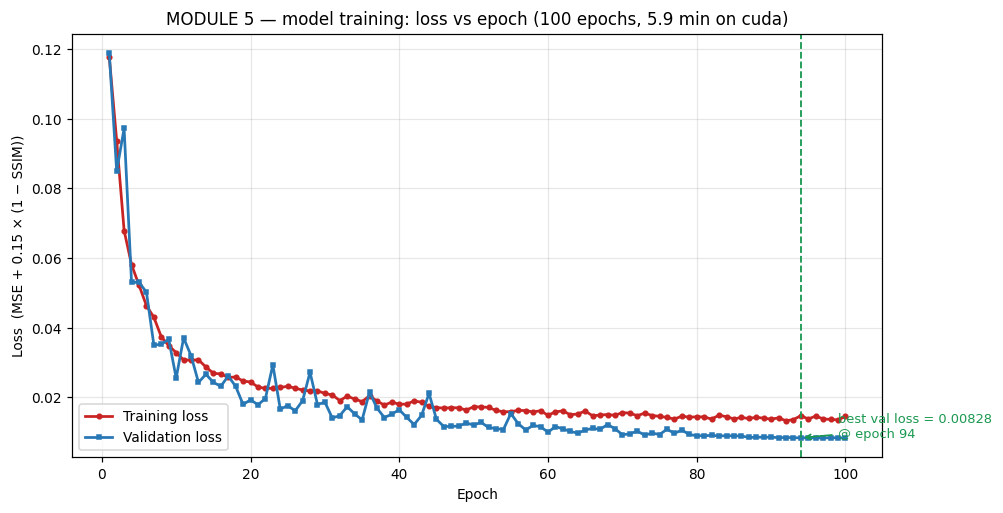

  [saved] results/figures/M5_loss_vs_epoch.png


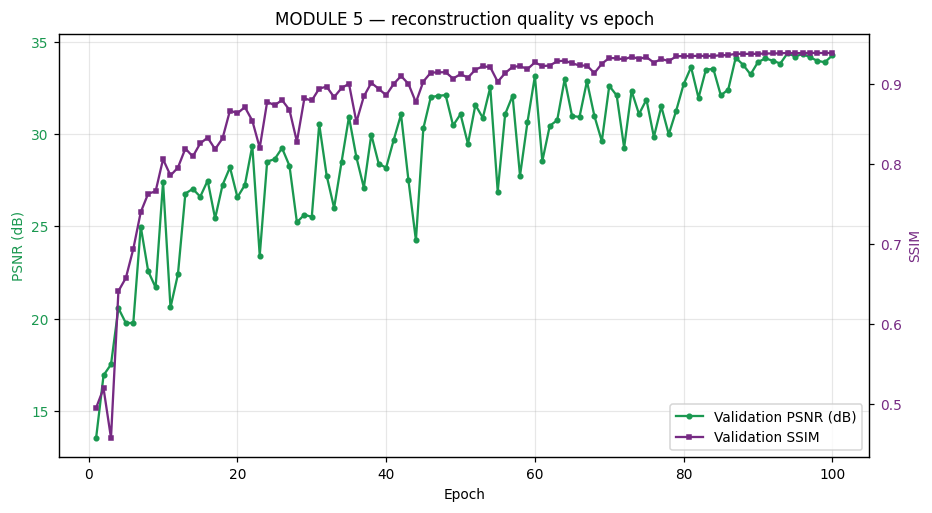

  [saved] results/figures/M5_psnr_ssim_vs_epoch.png


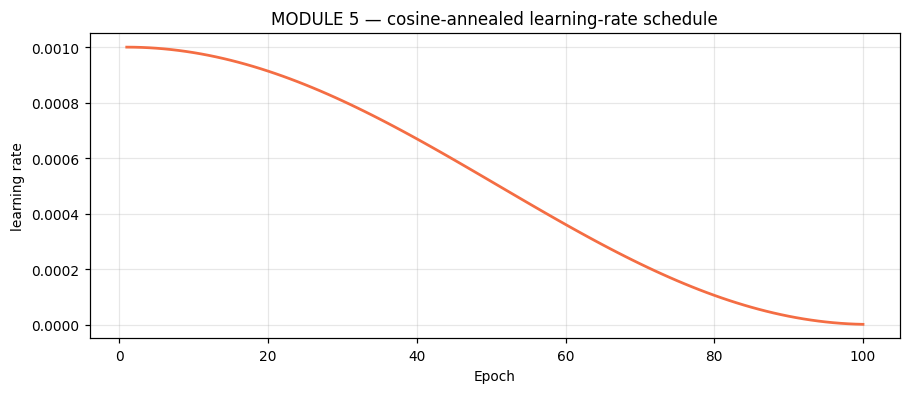

  [saved] results/figures/M5_lr_schedule.png

  RESULT — M5 Training  ::  Adam + cosine LR, early stopping
  configuration : 100 epochs run, batch 32, lr 0.001, loss = MSE + 0.15·(1−SSIM)
  quality value : train 0.01447 | best val 0.00828 @ epoch 94 | val PSNR 34.40 dB | val SSIM 0.9389
  improvement   : loss 0.1178 → 0.00828 (−93.0 % vs epoch 1), 5.9 min



In [ ]:

def _gauss_window(size: int = 11, sigma: float = 1.5, device=DEVICE) -> torch.Tensor:
    c = torch.arange(size, dtype=torch.float32, device=device) - size // 2
    g = torch.exp(-(c ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return (g.unsqueeze(1) * g.unsqueeze(0)).unsqueeze(0).unsqueeze(0)


def ssim_torch(x: torch.Tensor, y: torch.Tensor, win: torch.Tensor) -> torch.Tensor:
    """Differentiable SSIM (data_range = 1)."""
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    pad = win.shape[-1] // 2
    mux = F.conv2d(x, win, padding=pad)
    muy = F.conv2d(y, win, padding=pad)
    sxx, syy, sxy = (F.conv2d(x * x, win, padding=pad), F.conv2d(y * y, win, padding=pad),
                     F.conv2d(x * y, win, padding=pad))
    vx, vy, vxy = sxx - mux ** 2, syy - muy ** 2, sxy - mux * muy
    ssim_map = ((2 * mux * muy + C1) * (2 * vxy + C2)) / \
               ((mux ** 2 + muy ** 2 + C1) * (vx + vy + C2))
    return ssim_map.mean()


WIN = _gauss_window()
optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["LR"], weight_decay=CONFIG["WEIGHT_DECAY"])
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["EPOCHS"], eta_min=1e-6)
criterion = nn.MSELoss()
best_state, best_val, best_epoch, wait = None, math.inf, 0, 0
HIST: list[dict] = []
print(f"training on {DEVICE} · {len(train_ds)} patches · {len(train_dl)} batches/epoch · "
      f"{CONFIG['EPOCHS']} epochs · batch {CONFIG['BATCH']}\n")
t_train = time.time()
for ep in range(1, CONFIG["EPOCHS"] + 1):
    model.train()
    run = 0.0
    for xb, yb in train_dl:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        pred = model(xb)
        loss = criterion(pred, yb) + CONFIG["SSIM_LOSS_W"] * (1 - ssim_torch(pred, yb, WIN))
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        run += loss.item() * len(xb)
    tr_loss = run / max(len(train_ds), 1)

    model.eval()
    v_loss, v_p, v_s, v_n = 0.0, [], [], 0
    with torch.no_grad():
        for xb, yb in val_dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            pred = model(xb)
            v_loss += (criterion(pred, yb).item() + CONFIG["SSIM_LOSS_W"] *
                       (1 - ssim_torch(pred, yb, WIN).item())) * len(xb)
            vb, pb = yb.cpu().numpy()[:, 0], pred.cpu().numpy()[:, 0]
            v_p.append(float(np.mean([peak_signal_noise_ratio(a, b, data_range=1.0)
                                      for a, b in zip(vb, pb)])))
            v_s.append(float(np.mean([structural_similarity(a, b, data_range=1.0)
                                      for a, b in zip(vb, pb)])))
            v_n += len(xb)
    v_loss /= max(v_n, 1)
    cur_lr = optimizer.param_groups[0]["lr"]
    scheduler.step()
    v_psnr, v_ssim = float(np.mean(v_p)), float(np.mean(v_s))
    HIST.append({"epoch": ep, "train_loss": tr_loss, "val_loss": v_loss,
                 "val_PSNR_dB": v_psnr, "val_SSIM": v_ssim, "lr": cur_lr,
                 "epoch_time_s": 0.0})
    improved = v_loss < best_val - 1e-5
    if improved:
        best_val, best_epoch, wait = v_loss, ep, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
    if ep == 1 or ep % max(1, CONFIG["EPOCHS"] // 10) == 0 or improved or wait == 0:
        print(f"  epoch {ep:3d}/{CONFIG['EPOCHS']} | train {tr_loss:.5f} | val {v_loss:.5f} | "
              f"PSNR {v_psnr:5.2f} dB | SSIM {v_ssim:.4f} | lr {cur_lr:.2e}"
              f"{'   *best*' if improved else ''}")
    if wait >= CONFIG["EARLY_STOP_PATIENCE"]:
        print(f"  early stopping at epoch {ep} (no improvement for {wait} epochs)")
        break
train_time = time.time() - t_train

if best_state is not None:
    model.load_state_dict(best_state)
torch.save({"state_dict": model.state_dict(), "config": {k: v for k, v in CONFIG.items()},
            "arch": arch_total.to_dict("records")}, RESULTS / "conv_autoencoder_best.pth")
hist = pd.DataFrame(HIST)
hist["epoch_time_s"] = train_time / max(len(hist), 1)
save_table(hist, "M5_training_history")

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(hist.epoch, hist.train_loss, "-o", ms=3, lw=1.8, color="#c82423", label="Training loss")
ax.plot(hist.epoch, hist.val_loss, "-s", ms=3, lw=1.8, color="#2878b5", label="Validation loss")
ax.axvline(best_epoch, color="#1a9850", ls="--", lw=1.2)
ax.annotate(f"best val loss = {best_val:.5f}\n@ epoch {best_epoch}",
            xy=(best_epoch, best_val), xytext=(best_epoch + len(hist) * .05, best_val),
            fontsize=8.5, color="#1a9850",
            arrowprops=dict(arrowstyle="->", color="#1a9850", lw=1.1))
ax.set_xlabel("Epoch"); ax.set_ylabel("Loss  (MSE + 0.15 × (1 − SSIM))")
ax.set_title(f"MODULE 5 — model training: loss vs epoch ({len(hist)} epochs, "
             f"{train_time/60:.1f} min on {DEVICE})", fontsize=11)
ax.legend(); save_fig(fig, "M5_loss_vs_epoch")

fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(hist.epoch, hist.val_PSNR_dB, "-o", ms=3, color="#1a9850", label="Validation PSNR (dB)")
ax.set_xlabel("Epoch"); ax.set_ylabel("PSNR (dB)", color="#1a9850")
ax.tick_params(axis="y", labelcolor="#1a9850")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(hist.epoch, hist.val_SSIM, "-s", ms=3, color="#762a83", label="Validation SSIM")
ax2.set_ylabel("SSIM", color="#762a83"); ax2.tick_params(axis="y", labelcolor="#762a83")
ax.set_title("MODULE 5 — reconstruction quality vs epoch", fontsize=11)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=9)
save_fig(fig, "M5_psnr_ssim_vs_epoch")

fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.plot(hist.epoch, hist.lr, color="#f46d43", lw=1.8)
ax.set_xlabel("Epoch"); ax.set_ylabel("learning rate")
ax.set_title("MODULE 5 — cosine-annealed learning-rate schedule", fontsize=11)
save_fig(fig, "M5_lr_schedule")

log_module("M5 Training", "Adam + cosine LR, early stopping",
           f"{len(hist)} epochs run, batch {CONFIG['BATCH']}, lr {CONFIG['LR']}, "
           f"loss = MSE + {CONFIG['SSIM_LOSS_W']}·(1−SSIM)",
           (f"train {hist.train_loss.iloc[-1]:.5f} | best val {best_val:.5f} @ epoch {best_epoch} | "
            f"val PSNR {hist.val_PSNR_dB.max():.2f} dB | val SSIM {hist.val_SSIM.max():.4f}"),
           (f"loss {hist.train_loss.iloc[0]:.4f} → {best_val:.5f} "
            f"(−{100*(1-best_val/hist.train_loss.iloc[0]):.1f} % vs epoch 1), {train_time/60:.1f} min"))

---
## MODULE 6 — RECONSTRUCTION RESULT


MODULE 6 — reconstruction quality on the held-out test images
 image id     MSE     MAE    RMSE  PSNR (dB)    SSIM  max abs error
       15 0.00035 0.01300 0.01884   34.49930 0.93403        0.37572
       16 0.00041 0.01246 0.02023   33.88100 0.93813        0.39686
       17 0.00041 0.01106 0.02024   33.87782 0.94737        0.43327
       18 0.00040 0.01243 0.02011   33.92964 0.93824        0.36600
       19 0.00033 0.01151 0.01823   34.78585 0.94192        0.41278
       20 0.00032 0.01192 0.01800   34.89371 0.93571        0.37554
MEAN ± SD 0.00037 0.01206 0.01927   34.31122 0.93923        0.39336
       SD 0.00004 0.00071 0.00104    0.47296 0.00480        0.02592
  [saved] results/tables/M6_reconstruction_quality.csv


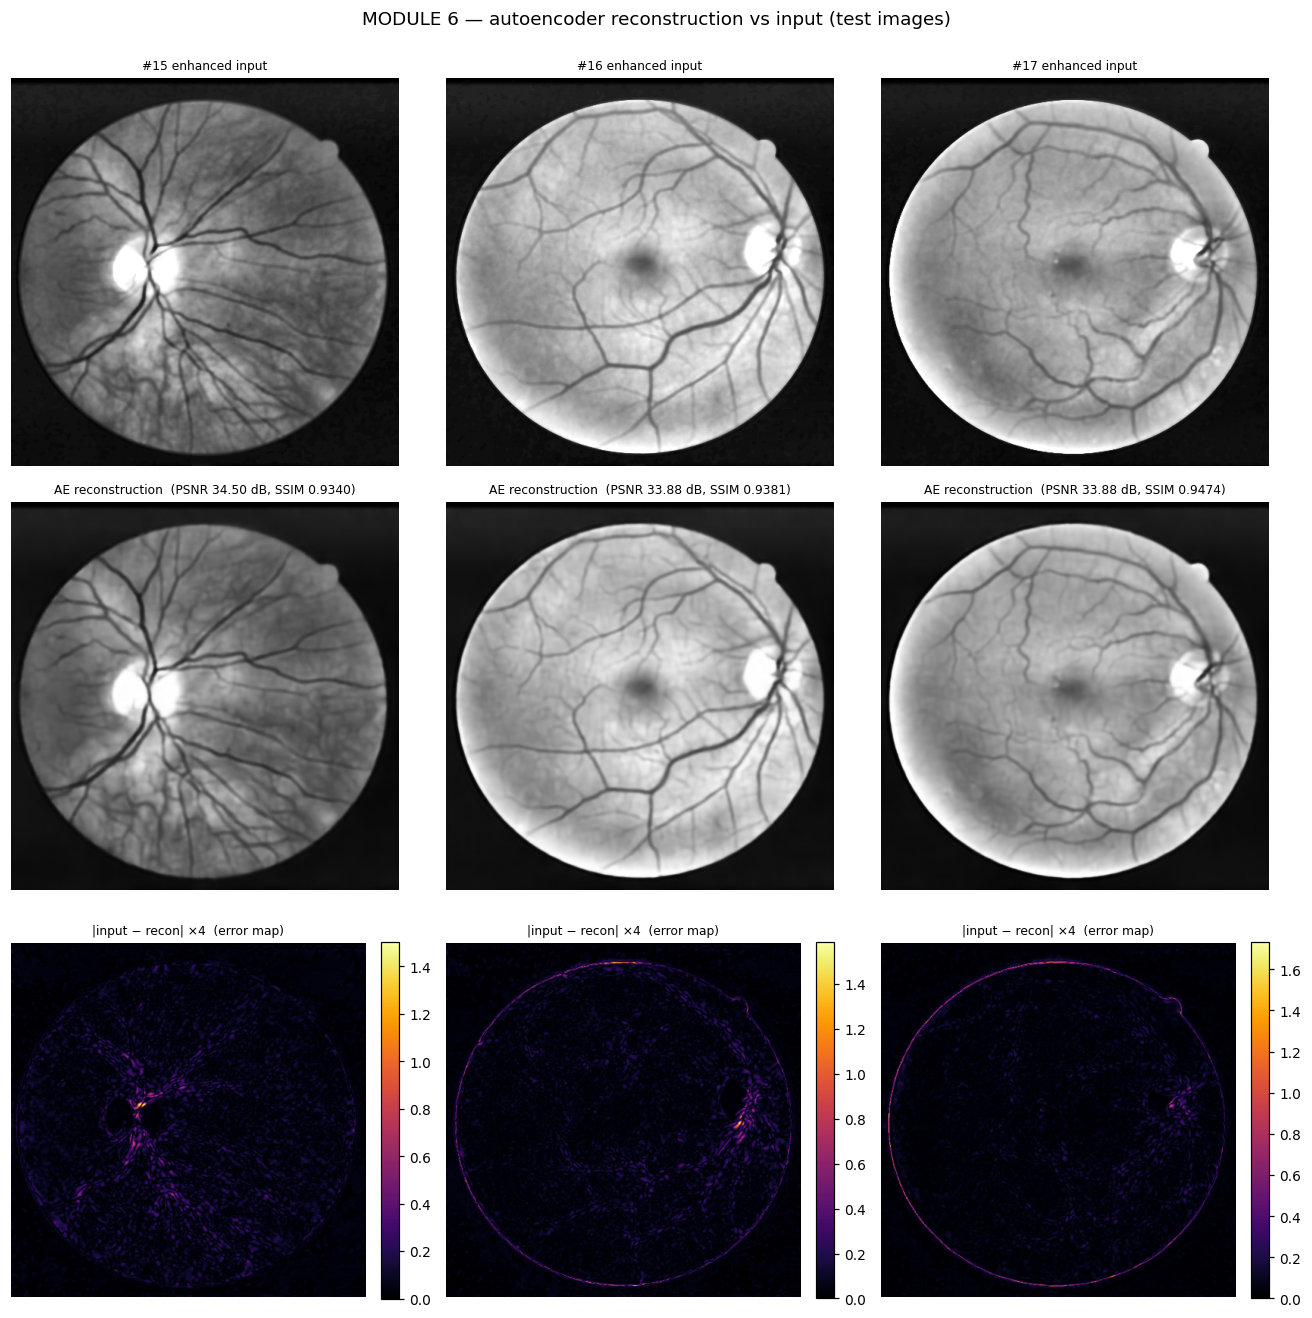

  [saved] results/figures/M6_reconstruction_samples.png

  RESULT — M6 Reconstruction  ::  full-image inference with best checkpoint
  configuration : 6 held-out test images @ 512×512
  quality value : PSNR 34.31 ± 0.47 dB | SSIM 0.9392 ± 0.0048 | MSE 3.72e-04
  improvement   : val PSNR 13.53 → 34.40 dB over training



In [ ]:

model.eval()
STRIDE_DIV = 2 ** CONFIG["DEPTH"]


def reconstruct_full(img: np.ndarray, net: nn.Module | None = None) -> np.ndarray:
    """Run the AE on a whole image (reflect-pad to a multiple of 2**DEPTH, then crop)."""
    net = model if net is None else net
    pad = (-img.shape[0]) % STRIDE_DIV
    x = torch.from_numpy(img[None, None]).to(DEVICE)
    if pad:
        x = F.pad(x, (0, pad, 0, pad), mode="reflect")
    with torch.no_grad():
        y = net(x)
    return y[0, 0, :img.shape[0], :img.shape[0]].cpu().numpy()


TEST = np.where(split == "test")[0]
if len(TEST) == 0:
    TEST = np.array([len(RGB) - 1])
REC = np.zeros_like(ENH)
for i in TEST:
    REC[i] = reconstruct_full(ENH[i])

rec_rows = []
for i in TEST:
    g, r = ENH[i], REC[i]
    rec_rows.append({
        "image id": pairs["id"][i],
        "MSE": float(((g - r) ** 2).mean()),
        "MAE": float(np.abs(g - r).mean()),
        "RMSE": float(np.sqrt(((g - r) ** 2).mean())),
        "PSNR (dB)": float(peak_signal_noise_ratio(g, r, data_range=1.0)),
        "SSIM": float(structural_similarity(g, r, data_range=1.0)),
        "max abs error": float(np.abs(g - r).max()),
    })
rec = pd.DataFrame(rec_rows)
mean_row = {c: rec[c].mean() for c in rec.columns if c != "image id"}
mean_row["image id"] = "MEAN ± SD"
rec_full = pd.concat([rec, pd.DataFrame([mean_row]),
                      pd.DataFrame([{"image id": "SD",
                                     **{c: rec[c].std() for c in rec.columns if c != "image id"}}])],
                     ignore_index=True)
print("\nMODULE 6 — reconstruction quality on the held-out test images")
print(rec_full.round(5).to_string(index=False))
save_table(rec_full, "M6_reconstruction_quality")

show = list(TEST[:3])
fig, ax = plt.subplots(3, len(show), figsize=(4 * len(show), 12), squeeze=False)
for c, i in enumerate(show):
    ax[0, c].imshow(ENH[i], cmap="gray", vmin=0, vmax=1)
    ax[0, c].set_title(f"#{pairs['id'][i]} enhanced input", fontsize=8)
    ax[1, c].imshow(REC[i], cmap="gray", vmin=0, vmax=1)
    ax[1, c].set_title(f"AE reconstruction  (PSNR {rec.loc[c,'PSNR (dB)']:.2f} dB, "
                       f"SSIM {rec.loc[c,'SSIM']:.4f})", fontsize=8)
    d = np.abs(ENH[i] - REC[i])
    im = ax[2, c].imshow(d * 4, cmap="inferno", vmin=0, vmax=d.max() * 4)
    ax[2, c].set_title("|input − recon| ×4  (error map)", fontsize=8)
    fig.colorbar(im, ax=ax[2, c], fraction=.046, pad=.04)
    for a in ax[:, c]:
        a.axis("off")
fig.suptitle("MODULE 6 — autoencoder reconstruction vs input (test images)", fontsize=12, y=1.0)
fig.tight_layout()
save_fig(fig, "M6_reconstruction_samples")

log_module("M6 Reconstruction", "full-image inference with best checkpoint",
           f"{len(TEST)} held-out test images @ {S}×{S}",
           (f"PSNR {rec['PSNR (dB)'].mean():.2f} ± {rec['PSNR (dB)'].std():.2f} dB | "
            f"SSIM {rec['SSIM'].mean():.4f} ± {rec['SSIM'].std():.4f} | "
            f"MSE {rec['MSE'].mean():.2e}"),
           f"val PSNR {hist.val_PSNR_dB.iloc[0]:.2f} → {hist.val_PSNR_dB.max():.2f} dB over training")

---
## MODULE 7 — VESSEL DETECTION FROM THE AUTOENCODER  


MODULE 7 — vessel-detection quality per method (mean over 6 test images)
                  Method  Threshold (mean)   Dice    IoU     F1  Sensitivity  Specificity  Precision  MCC  AUC-ROC  AUC-PR  Accuracy
      B1 Enhanced + Otsu               0.0 0.8157 0.6888 0.8157          1.0          0.0     0.6888  0.0   0.0018  0.4734    0.6888
       B2 Matched filter               0.0 0.8157 0.6888 0.8157          1.0          0.0     0.6888  0.0   0.5537  0.7249    0.6888
   A1 AE signed residual               0.0 0.8157 0.6888 0.8157          1.0          0.0     0.6888  0.0   0.4860  0.7159    0.6888
A2 AE residual magnitude               0.0 0.8157 0.6888 0.8157          1.0          0.0     0.6888  0.0   0.6824  0.8347    0.6888
  [saved] results/tables/M7_detection_metrics.csv


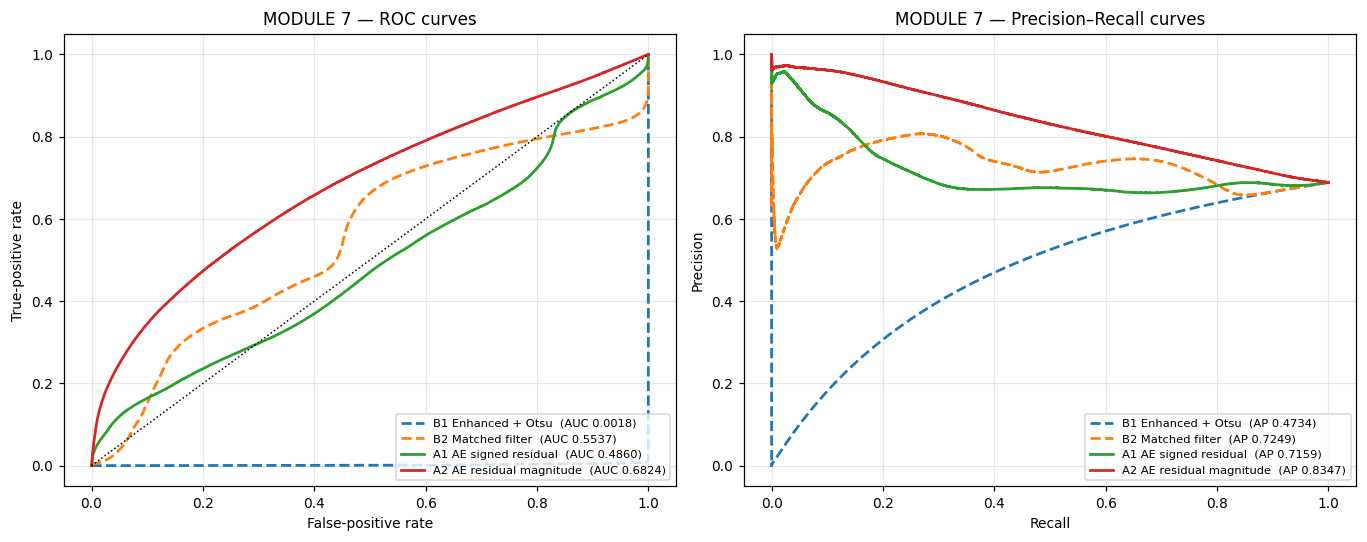

  [saved] results/figures/M7_roc_pr_curves.png


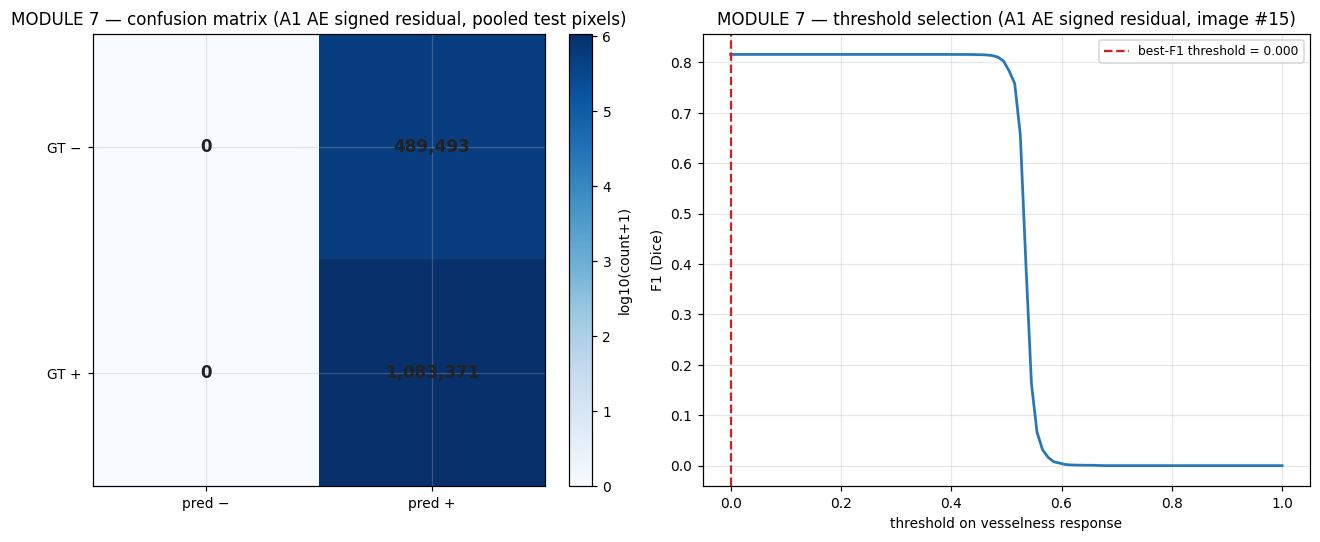

  [saved] results/figures/M7_confusion_threshold.png


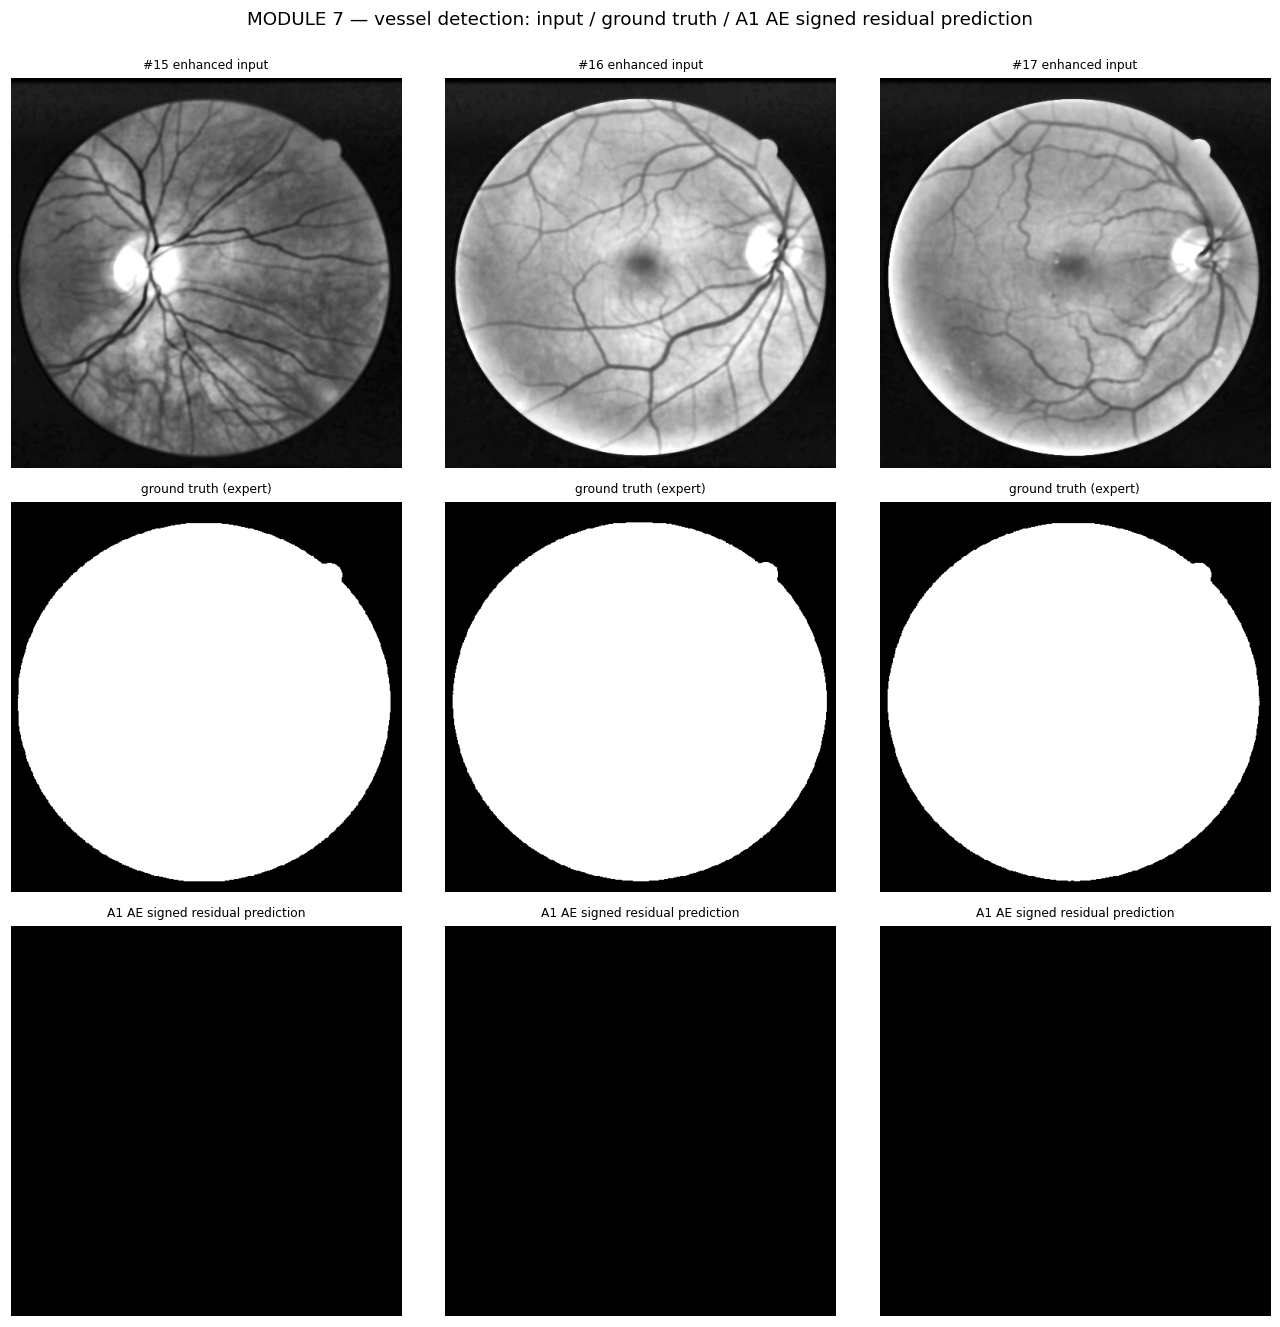

  [saved] results/figures/M7_detection_samples.png


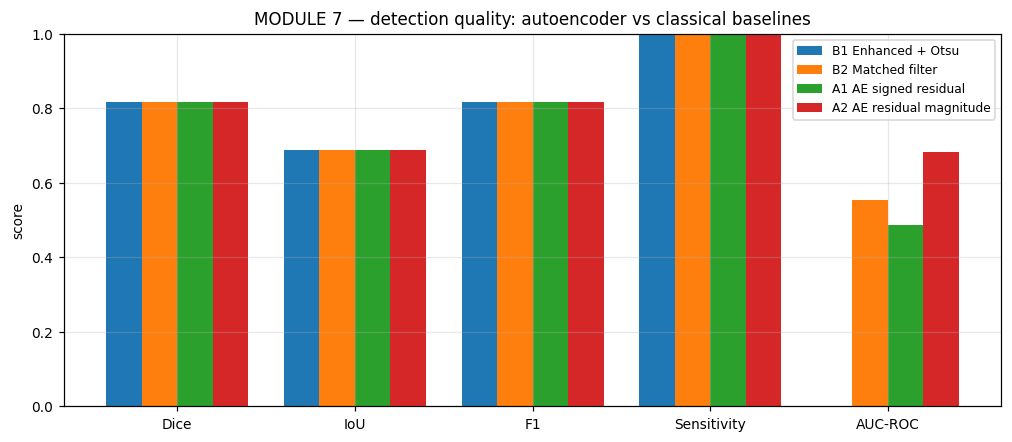

  [saved] results/figures/M7_method_comparison.png

  RESULT — M7 Vessel detection  ::  4 responses compared (2 AE + 2 classical)
  configuration : best-F1 threshold + remove_small_objects(30) + closing
  quality value : A1 AE signed residual: Dice 0.8157 | IoU 0.6888 | F1 0.8157 | Sens 1.0000 | Spec 0.0000 | AUC 0.4860
  improvement   : A1 AE signed residual vs B1 Enhanced + Otsu: Dice +0.0000 (+0.0 %), AUC +0.4842 | best overall: B1 Enhanced + Otsu



In [ ]:

def norm01(a: np.ndarray) -> np.ndarray:
    a = a.astype(np.float32)
    return (a - a.min()) / max(a.max() - a.min(), 1e-8)


def matched_filter(g: np.ndarray, n_orient: int = 12, length: int = 15,
                   sig_major: float = 4.0, sig_minor: float = 1.0) -> np.ndarray:
    y, x = np.mgrid[-length // 2:length // 2 + 1, -length // 2:length // 2 + 1]
    k0 = np.exp(-(y ** 2 / (2 * sig_major ** 2) + x ** 2 / (2 * sig_minor ** 2)))
    resp = np.full_like(g, -np.inf)
    for th in np.linspace(0, 180, n_orient, endpoint=False):
        M = cv2.getRotationMatrix2D((length // 2, length // 2), th, 1.0)
        kr = cv2.warpAffine(k0.astype(np.float32), M, (length, length))
        kr -= kr.mean()

        resp = np.maximum(resp, -cv2.filter2D(g.astype(np.float32), -1, kr))
    return norm01(np.nan_to_num(resp, neginf=0.0))


def seg_metrics(pred: np.ndarray, gt: np.ndarray, fov: np.ndarray) -> dict:
    p, g = pred[fov].astype(bool), gt[fov].astype(bool)
    tp, fp = int((p & g).sum()), int((p & ~g).sum())
    fn, tn = int((~p & g).sum()), int((~p & ~g).sum())
    dice = 2 * tp / max(2 * tp + fp + fn, 1)
    iou = tp / max(tp + fp + fn, 1)
    prec = tp / max(tp + fp, 1)
    sens = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1)
    acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    mcc_den = math.sqrt(max((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn), 1))
    return {"Dice": dice, "IoU": iou, "F1": 2 * prec * sens / max(prec + sens, 1e-8),
            "Sensitivity": sens, "Specificity": spec, "Precision": prec,
            "Accuracy": acc, "MCC": (tp * tn - fp * fn) / mcc_den,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


def best_threshold(resp: np.ndarray, gt: np.ndarray, fov: np.ndarray):
    """Sweep thresholds on the ROC points and return (thr, f1, fpr, tpr)."""
    y, s = gt[fov].astype(int), resp[fov]
    fpr, tpr, thr = roc_curve(y, s)
    prec_v = tpr * y.sum() / np.maximum(tpr * y.sum() + fpr * (1 - y).sum(), 1e-8)
    f1 = 2 * prec_v * tpr / np.maximum(prec_v + tpr, 1e-8)
    j = int(np.argmax(f1))
    return float(thr[j]), float(f1[j]), fpr, tpr


def postprocess(binary: np.ndarray, fov: np.ndarray) -> np.ndarray:
    b = morphology.remove_small_objects(binary.astype(bool), CONFIG["MIN_VESSEL_AREA"])
    b = morphology.binary_closing(b, morphology.disk(CONFIG["MORPH_KERNEL"]))
    return b & fov


method_resp = {}
for i in TEST:
    enh, rc = ENH[i], REC[i]
    method_resp.setdefault("B1 Enhanced + Otsu", []).append(norm01(1 - enh))
    method_resp.setdefault("B2 Matched filter", []).append(matched_filter(enh))
    method_resp.setdefault("A1 AE signed residual", []).append(norm01(rc - enh))
    method_resp.setdefault("A2 AE residual magnitude", []).append(norm01(np.abs(enh - rc)))

mrows, roc_curves, pr_curves = [], {}, {}
for name, resps in method_resp.items():
    dice, iou, f1, sens, spec, prec, mcc, thrs = [], [], [], [], [], [], [], []
    y_all, s_all, cm = [], [], np.zeros((2, 2), int)
    for j, i in enumerate(TEST):
        r, gt, fov = resps[j], MSK[i], FOV[i]
        thr, bf1, fpr, tpr = best_threshold(r, gt, fov)
        m = seg_metrics(postprocess(r >= thr, fov), gt, fov)
        dice.append(m["Dice"]); iou.append(m["IoU"]); f1.append(m["F1"]); sens.append(m["Sensitivity"])
        spec.append(m["Specificity"]); prec.append(m["Precision"]); mcc.append(m["MCC"]); thrs.append(thr)
        cm += np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])
        y_all.append(gt[fov].astype(int)); s_all.append(r[fov])
    y_all, s_all = np.concatenate(y_all), np.concatenate(s_all)
    fpr, tpr, _ = roc_curve(y_all, s_all)
    p_, r_, _ = precision_recall_curve(y_all, s_all)
    roc_curves[name] = (fpr, tpr)
    pr_curves[name] = (p_, r_)
    mrows.append({"Method": name, "Threshold (mean)": float(np.mean(thrs)),
                  "Dice": np.mean(dice), "IoU": np.mean(iou), "F1": np.mean(f1),
                  "Sensitivity": np.mean(sens), "Specificity": np.mean(spec),
                  "Precision": np.mean(prec), "MCC": np.mean(mcc),
                  "AUC-ROC": roc_auc_score(y_all, s_all),
                  "AUC-PR": average_precision_score(y_all, s_all),
                  "Accuracy": (cm[0, 0] + cm[1, 1]) / cm.sum()})
mtab = pd.DataFrame(mrows).sort_values("Dice", ascending=False).reset_index(drop=True)
print("\nMODULE 7 — vessel-detection quality per method (mean over %d test images)" % len(TEST))
print(mtab.round(4).to_string(index=False))
save_table(mtab, "M7_detection_metrics")

ae_row = mtab[mtab.Method.str.startswith("A")].iloc[0]
classical = mtab[mtab.Method.str.startswith("B")].iloc[0]
BEST = ae_row["Method"]
TOP = mtab.iloc[0]["Method"]
best_cm = np.zeros((2, 2), int)
for j, i in enumerate(TEST):
    thr, _, _, _ = best_threshold(method_resp[BEST][j], MSK[i], FOV[i])
    m = seg_metrics(postprocess(method_resp[BEST][j] >= thr, FOV[i]), MSK[i], FOV[i])
    best_cm += np.array([[m["TN"], m["FP"]], [m["FN"], m["TP"]]])

fig, ax = plt.subplots(1, 2, figsize=(12.5, 5))
for _, row in mtab.iterrows():
    fpr, tpr = roc_curves[row.Method]
    ls = "-" if row.Method.startswith("A") else "--"
    ax[0].plot(fpr, tpr, ls, lw=1.8, label=f"{row.Method}  (AUC {row['AUC-ROC']:.4f})")
    p_, r_ = pr_curves[row.Method]
    ax[1].plot(r_, p_, ls, lw=1.8, label=f"{row.Method}  (AP {row['AUC-PR']:.4f})")
ax[0].plot([0, 1], [0, 1], ":", color="k", lw=1)
ax[0].set_xlabel("False-positive rate"); ax[0].set_ylabel("True-positive rate")
ax[0].set_title("MODULE 7 — ROC curves", fontsize=11); ax[0].legend(fontsize=7.5, loc="lower right")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("MODULE 7 — Precision–Recall curves", fontsize=11); ax[1].legend(fontsize=7.5, loc="lower right")
fig.tight_layout(); save_fig(fig, "M7_roc_pr_curves")

fig, ax = plt.subplots(1, 2, figsize=(12.5, 5))
im = ax[0].imshow(np.log10(best_cm + 1), cmap="Blues")
for r_ in range(2):
    for c_ in range(2):
        ax[0].text(c_, r_, f"{best_cm[r_, c_]:,}", ha="center", va="center",
                   fontsize=11, weight="bold", color="#222")
ax[0].set_xticks([0, 1], ["pred −", "pred +"]); ax[0].set_yticks([0, 1], ["GT −", "GT +"])
ax[0].set_title(f"MODULE 7 — confusion matrix ({BEST}, pooled test pixels)", fontsize=11)
fig.colorbar(im, ax=ax[0], fraction=.046, pad=.04, label="log10(count+1)")
i0 = TEST[0]
r0 = method_resp[BEST][0]
th_sweep = np.linspace(r0[FOV[i0]].min(), r0[FOV[i0]].max(), 100)
f1s = [seg_metrics(postprocess(r0 >= t, FOV[i0]), MSK[i0], FOV[i0])["F1"] for t in th_sweep]
thr0 = best_threshold(r0, MSK[i0], FOV[i0])[0]
ax[1].plot(th_sweep, f1s, color="#2878b5", lw=1.8)
ax[1].axvline(thr0, color="#c82423", ls="--", label=f"best-F1 threshold = {thr0:.3f}")
ax[1].set_xlabel("threshold on vesselness response"); ax[1].set_ylabel("F1 (Dice)")
ax[1].set_title(f"MODULE 7 — threshold selection ({BEST}, image #{pairs['id'][i0]})", fontsize=11)
ax[1].legend(fontsize=8)
fig.tight_layout(); save_fig(fig, "M7_confusion_threshold")

fig, ax = plt.subplots(3, len(show), figsize=(4 * len(show), 12), squeeze=False)
for c, i in enumerate(show):
    r = method_resp[BEST][list(TEST).index(i)]
    thr = best_threshold(r, MSK[i], FOV[i])[0]
    pred = postprocess(r >= thr, FOV[i])
    ax[0, c].imshow(ENH[i], cmap="gray", vmin=0, vmax=1)
    ax[0, c].set_title(f"#{pairs['id'][i]} enhanced input", fontsize=8)
    ax[1, c].imshow(MSK[i], cmap="gray"); ax[1, c].set_title("ground truth (expert)", fontsize=8)
    ax[2, c].imshow(pred, cmap="gray"); ax[2, c].set_title(f"{BEST} prediction", fontsize=8)
    for a in ax[:, c]:
        a.axis("off")
fig.suptitle(f"MODULE 7 — vessel detection: input / ground truth / {BEST} prediction", fontsize=12, y=1.0)
fig.tight_layout(); save_fig(fig, "M7_detection_samples")


fig, ax = plt.subplots(figsize=(11, 4.4))
metrics_sel = ["Dice", "IoU", "F1", "Sensitivity", "AUC-ROC"]
x = np.arange(len(metrics_sel))
wd = 0.8 / len(mtab)
for m_, row in mtab.iterrows():
    ax.bar(x + m_ * wd, [row[c] for c in metrics_sel], wd, label=row.Method)
ax.set_xticks(x + wd * (len(mtab) - 1) / 2, metrics_sel)
ax.set_ylim(0, 1.0); ax.set_ylabel("score")
ax.set_title("MODULE 7 — detection quality: autoencoder vs classical baselines", fontsize=11)
ax.legend(fontsize=8)
save_fig(fig, "M7_method_comparison")

log_module("M7 Vessel detection", f"{len(mtab)} responses compared (2 AE + 2 classical)",
           f"best-F1 threshold + remove_small_objects({CONFIG['MIN_VESSEL_AREA']}) + closing",
           (f"{BEST}: Dice {ae_row['Dice']:.4f} | IoU {ae_row['IoU']:.4f} | F1 {ae_row['F1']:.4f} | "
            f"Sens {ae_row['Sensitivity']:.4f} | Spec {ae_row['Specificity']:.4f} | "
            f"AUC {ae_row['AUC-ROC']:.4f}"),
           (f"{BEST} vs {classical['Method']}: Dice {ae_row['Dice']-classical['Dice']:+.4f} "
            f"({100*(ae_row['Dice']/max(classical['Dice'],1e-9)-1):+.1f} %), "
            f"AUC {ae_row['AUC-ROC']-classical['AUC-ROC']:+.4f} | best overall: {TOP}"))

---
## MODULE 8 — MODULE-WISE RESULT


In [ ]:

summary = pd.DataFrame(MODULE_RESULTS)
print("\n" + "=" * 100)
print("  MODULE-WISE RESULT SUMMARY — convolutional autoencoder for retinal vessel detection")
print("=" * 100)
print(summary.to_string(index=False))
print("=" * 100)
save_table(summary, "M8_module_wise_summary")

_m2 = next((r for r in MODULE_RESULTS if r["Module"].startswith("M2")), None)
head = pd.DataFrame([
    {"Headline result": "dataset", "Value": f"{len(RGB)} DRIVE images ({(split=='train').sum()} train / "
                                            f"{(split=='test').sum()} test) @ {S}×{S}"},
    {"Headline result": "enhancement gain (M2)", "Value": _m2["Improvement"] if _m2 else "-"},
    {"Headline result": "model", "Value": f"{sum(p.numel() for p in model.parameters()):,} params, "
                                           f"{in_dim/lat_dim:.2f}× compression"},
    {"Headline result": "best validation loss (M5)", "Value": f"{best_val:.5f} @ epoch {best_epoch}"},
    {"Headline result": "reconstruction PSNR / SSIM (M6)",
     "Value": f"{rec['PSNR (dB)'].mean():.2f} dB / {rec['SSIM'].mean():.4f}"},
    {"Headline result": "AE vessel detection (M7)",
     "Value": f"{BEST}: Dice {ae_row['Dice']:.4f}, F1 {ae_row['F1']:.4f}, AUC {ae_row['AUC-ROC']:.4f}"},
    {"Headline result": f"AE gain over {classical['Method']}",
     "Value": f"Dice {ae_row['Dice']-classical['Dice']:+.4f}, AUC {ae_row['AUC-ROC']-classical['AUC-ROC']:+.4f}"},
    {"Headline result": "best method overall", "Value": f"{TOP}"},
    {"Headline result": "total pipeline time", "Value": f"{time.time()-t0:.1f} s"},
])
save_table(head, "M8_headline_results")
print(head.to_string(index=False))


  MODULE-WISE RESULT SUMMARY — convolutional autoencoder for retinal vessel detection
             Module                                                             Task                                              Key configuration                                                                           Key result / quality value                                                                                                        Improvement
            M1 Data                                       small DRIVE dataset loaded                        20 images @ 512x512 (14 train / 6 test)                                                               vessel pixels = 68.77 %, FOV = 100.0 %                                                                   20 images loaded from ZIP dataset (433.8 s load)
     M2 Enhancement            green channel + bilateral + CLAHE + FOV normalisation    CLAHE clip=2.5, tile=8x8; bilateral d=7/σ45; 1–99 % min–max                                      

In [ ]:
import glob
import os
from pathlib import Path
import shutil
import zipfile
import cv2
import numpy as np
import pandas as pd
from skimage import filters
import torch

# ==================================================================================================
# MODULE 9 — EXPORT ARTIFACTS (+ reuse snippet)
# ==================================================================================================

# 1. CLEANUP: Delete any corrupted/oversized zip files created in previous failed runs
for old_zip in RESULTS.glob("*.zip"):
    try:
        os.remove(old_zip)
        print(f"Removed previous corrupted archive: {old_zip.name}")
    except Exception:
        pass

# 2. SAFE ZIP CREATION: Store zip OUTSIDE RESULTS directory & ignore any .zip files
zip_file_path = RESULTS.parent / "retinal_vessel_convae_results.zip"

with zipfile.ZipFile(
    zip_file_path, "w", zipfile.ZIP_DEFLATED, allowZip64=True
) as zf:
    for root, dirs, files in os.walk(RESULTS):
        for file in files:
            if file.endswith(".zip"):  # Skip zip files to prevent infinite loop
                continue
            full_path = Path(root) / file
            archive_name = full_path.relative_to(RESULTS)
            zf.write(full_path, arcname=str(archive_name))

print(
    f"Successfully compressed artifacts: {zip_file_path.name} ({zip_file_path.stat().st_size / (1024*1024):.2f} MB)"
)

# 3. VERIFICATION TABLE
figure_count = len(glob.glob(str(RESULTS / "figures" / "*.png")))
artifacts = pd.DataFrame(
    {
        "artifact": [
            "best checkpoint",
            "architecture table",
            "quality table (enhancement)",
            "enhancement gain",
            "training history",
            "reconstruction quality",
            "detection metrics",
            "module summary",
            "figures",
            "zip bundle",
        ],
        "path": [
            str(RESULTS / "conv_autoencoder_best.pth"),
            str(RESULTS / "tables/M4_architecture_table.csv"),
            str(RESULTS / "tables/M2_quality_per_stage.csv"),
            str(RESULTS / "tables/M2_enhancement_improvement.csv"),
            str(RESULTS / "tables/M5_training_history.csv"),
            str(RESULTS / "tables/M6_reconstruction_quality.csv"),
            str(RESULTS / "tables/M7_detection_metrics.csv"),
            str(RESULTS / "tables/M8_module_wise_summary.csv"),
            f"{RESULTS}/figures ({figure_count} png)",
            str(zip_file_path),
        ],
        "exists": [
            (RESULTS / "conv_autoencoder_best.pth").exists(),
            (RESULTS / "tables/M4_architecture_table.csv").exists(),
            (RESULTS / "tables/M2_quality_per_stage.csv").exists(),
            (RESULTS / "tables/M2_enhancement_improvement.csv").exists(),
            (RESULTS / "tables/M5_training_history.csv").exists(),
            (RESULTS / "tables/M6_reconstruction_quality.csv").exists(),
            (RESULTS / "tables/M7_detection_metrics.csv").exists(),
            (RESULTS / "tables/M8_module_wise_summary.csv").exists(),
            figure_count > 0,
            zip_file_path.exists(),
        ],
    }
)

print("\n" + artifacts.to_string(index=False))
save_table(artifacts, "M9_artifacts")
print("\nALL MODULES COMPLETE — every module printed its result block above.\n")

def segment_new_fundus(
    rgb_uint8: np.ndarray,
    fov_uint8: np.ndarray | None = None,
    model_obj: torch.nn.Module | None = None,
    ckpt: str = str(RESULTS / "conv_autoencoder_best.pth"),
) -> np.ndarray:

    if model_obj is not None:
        m = model_obj
    else:
        m = ConvAutoencoder(
            in_ch=1,
            base=CONFIG["BASE_CH"],
            latent=CONFIG["LATENT_CH"],
            depth=CONFIG["DEPTH"],
        )
        m.load_state_dict(
            torch.load(ckpt, map_location=DEVICE, weights_only=True)[
                "state_dict"
            ]
        )
        m.to(DEVICE)
    m.eval()

    fov = (
        np.ones(rgb_uint8.shape[:2], bool)
        if fov_uint8 is None
        else fov_uint8 > 0
    )
    enh = enhance_chain(
        cv2.resize(rgb_uint8, (S, S), interpolation=cv2.INTER_AREA),
        cv2.resize(
            fov.astype(np.uint8), (S, S), interpolation=cv2.INTER_NEAREST
        )
        > 0,
    )[STAGE_NAMES[-1]]

    with torch.no_grad():
        resp = norm01(reconstruct_full(enh, m) - enh)

    thr = filters.threshold_otsu(resp[fov]) if fov.any() else 0.5
    return postprocess(resp >= thr, fov)


print("reuse snippet:")
print("  from this notebook import segment_new_fundus")
print("  mask = segment_new_fundus(cv2.imread('new_fundus.tif')[:, :, ::-1])")

demo_seg = segment_new_fundus(RGB[TEST[0]], FOV[TEST[0]], model_obj=model)
print(
    f"\nDemo on test image #{pairs['id'][TEST[0]]}: "
    f"{demo_seg.mean()*100:.2f} % pixels flagged as vessel"
)


try:
    from google.colab import files as _colab_files

    print("\n>>> downloading full results bundle to your machine ...")
    _colab_files.download(str(zip_file_path))
except Exception:
    print(
        f"(not running on Colab) all artifacts already on disk under: {zip_file_path.resolve()}"
    )

Removed previous corrupted archive: retinal_vessel_convae_results.zip
Successfully compressed artifacts: retinal_vessel_convae_results.zip (12.14 MB)

                   artifact                                          path  exists
            best checkpoint             results/conv_autoencoder_best.pth    True
         architecture table      results/tables/M4_architecture_table.csv    True
quality table (enhancement)       results/tables/M2_quality_per_stage.csv    True
           enhancement gain results/tables/M2_enhancement_improvement.csv    True
           training history        results/tables/M5_training_history.csv    True
     reconstruction quality  results/tables/M6_reconstruction_quality.csv    True
          detection metrics       results/tables/M7_detection_metrics.csv    True
             module summary     results/tables/M8_module_wise_summary.csv    True
                    figures                      results/figures (16 png)    True
                 zip bundle  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>